# Capacity-Aware Early-Warning System: Pilot on Development Data

| | |
|---|---|
| **Author** | Chia Yu Hang |
| **Student ID** | *H00450391* |
| **Supervisor** | *Dr Zi Hau Chin* |
| **Date** | 24 November 2026 |

## What this notebook does
This notebook runs the **feasibility pilot** of the capacity-aware early-warning system on
**development data only**: the model-fitting partition (`fit`, the 2013J presentations) and the
probability-calibration partition (`pcal`). It starts from the seven raw OULAD tables and goes
through these steps in order:

1. Assign whole presentations to partitions, keeping each student in one partition only.
2. Build leakage-safe feature sets at Days 14, 28 and 42.
3. Train HGB and logistic-regression models on `fit`.
4. Platt-calibrate them and build class-conditional LAC conformal sets, cross-fitted over three
   student-grouped folds of `pcal`.
5. Route students under fixed per-module capacity with six methods.
6. Explain one recommendation with Kernel SHAP and check fairness of access with Fairlearn.

The conformal-calibration (`ccal`) and test (`test`, 2014J) partitions are only *assigned* here.
Their rows are dropped before any modelling, the notebook stops if any of them reappear, and no
outcome from them is ever printed. The final evaluation is not part of this notebook.

**Nothing is written to disk.** Saved pilot outputs are only *read*, and only to confirm that this
notebook reproduces them.

## How to run it
- **Python 3.14.2** with pandas 3.0.1, numpy 2.4.3, scikit-learn 1.9.1, scipy, matplotlib 3.11.2,
  interpret 0.7.8 (interpretml, for Kernel SHAP; needs the `shap` package, 0.54.1 used),
  fairlearn 0.15.0, pyarrow 26.0.1 and jupyter. These are the versions in `pilot/environment.txt`;
  cell 0.2 prints yours and flags any difference.
- **Files.** Put this notebook in the project folder next to `routing_engine.py` and `capacity.py`,
  which it imports. Put the OULAD files in `DATA_DIR` (default: the same folder). Each table can be
  `name.csv` or `name.csv.zip`, and `studentVle` may be one file or split into
  `studentVle_0 … studentVle_7`.
- Use **Kernel → Restart & Run All**. A full run takes **about 19 minutes** on the author's laptop (about 15 of them in the 100 re-split coverage check in §5.2; set `N_RESPLITS` lower for a quick test run)
  (Windows 11, Python 3.14). Every check is recorded, and the run stops at the first one that fails.

## Data source and licence
Open University Learning Analytics Dataset (OULAD): <https://analyse.kmi.open.ac.uk/open_dataset>.
Kuzilek, J., Hlosta, M. and Zdrahal, Z. (2017) "Open University Learning Analytics dataset",
*Scientific Data* 4, 170171. Licensed under **CC BY 4.0**
(<https://creativecommons.org/licenses/by/4.0/>).

## 0.1 Configuration: all seeds and settings in one place
Every random step uses `RS = 42`. No value below was tuned on the data.

In [1]:
import glob
import math
import os
import platform
import sys
import time
import warnings
from collections import defaultdict

T_START = time.time()

# ---- Paths ----
DATA_DIR = "."                         # folder with the OULAD csv / csv.zip files
PREPARED_DIR = "prepared"              # optional: saved checkpoint files, used only to cross-check
PILOT_DIR = "pilot"                    # optional: saved pilot outputs, used only to cross-check

# ---- Seeds ----
RS = 42                                # every random_state / RNG seed in this notebook
N_RESPLITS = 100                       # 100 re-split coverage check (seeds 0..99)
N_BOOT = 1000                          # student-level bootstrap for fairness intervals

# ---- Study design ----
CHECKPOINTS = [14, 28, 42]             # end of Day T
WEEK = {14: 2, 28: 4, 42: 6}
DELAY = {"TMA": 14, "CMA": 7}          # marking delay: a score is visible at T only if
                                       # max(date_submitted, due_date) + delay <= T
ALPHA = 0.10                           # primary conformal level
ALPHAS = [0.05, 0.10, 0.15, 0.20]      # alpha sweep (evidence only; 0.10 is not re-chosen)
CUTOFF = 0.5                           # "high risk" probability cutoff
N_BINS = 10                            # ECE / reliability bins
CLIP_EPS = 1e-6                        # logit clipping
K_DEFAULT, R_DEFAULT, B_DEFAULT = 10, 5, 25   # capacity per module (see capacity.py)
AGE_MERGE = {"0-35": "0-35", "35-55": "35 and over", "55<=": "35 and over"}

import numpy as np
np.random.seed(RS)
print(f"RS = {RS}; alpha = {ALPHA}; cutoff = {CUTOFF}; capacity K = {K_DEFAULT}, R = {R_DEFAULT}, B = {B_DEFAULT}")

RS = 42; alpha = 0.1; cutoff = 0.5; capacity K = 10, R = 5, B = 25


## 0.2 Packages, versions and the check register
Every automated check in the notebook calls `check(...)`. A failed check stops the run, and §8
lists every check with its result.

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import scipy
import sklearn
import fairlearn
import interpret
from fairlearn.metrics import MetricFrame, count
from interpret.blackbox import ShapKernel
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import routing_engine as RE
from capacity import ModuleCapacity, capacity_for_all_modules, print_capacity_table

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 200)

EXPECTED_VERSIONS = {"python": "3.14.2", "pandas": "3.0.1", "numpy": "2.4.3", "scikit-learn": "1.9.1",
                     "matplotlib": "3.11.2", "interpret": "0.7.8", "fairlearn": "0.15.0"}
found = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
         "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
         "interpret": interpret.__version__, "fairlearn": fairlearn.__version__}
display(pd.DataFrame([dict(package=k, used_in_pilot=v, this_run=found[k],
                           same="yes" if found[k] == v else "DIFFERENT - results may differ slightly")
                      for k, v in EXPECTED_VERSIONS.items()]))
print("platform:", platform.platform(), "| scipy", scipy.__version__)

CHECKS = []


def check(section, name, ok, detail=""):
    # Record one automated check, stop the notebook if it fails.
    ok = bool(ok)
    CHECKS.append(dict(section=section, check=name, result="pass" if ok else "FAIL", detail=str(detail)))
    if not ok:
        raise AssertionError(f"CHECK FAILED [{section}] {name}: {detail}")


def skipped(section, name, why):
    CHECKS.append(dict(section=section, check=name, result="skipped", detail=why))


check("0", "routing_engine.py uses the v5 defaults",
      RE.FOLLOWUP_REVIEW and RE.FOLLOWUP_LAST and RE.CONTACTED_CAN_REVIEW is False and RE.COUNT_BEFORE_FIRST_SELECTION,
      dict(FOLLOWUP_REVIEW=RE.FOLLOWUP_REVIEW, FOLLOWUP_LAST=RE.FOLLOWUP_LAST,
           CONTACTED_CAN_REVIEW=RE.CONTACTED_CAN_REVIEW, COUNT_BEFORE_FIRST_SELECTION=RE.COUNT_BEFORE_FIRST_SELECTION))

,package,used_in_pilot,this_run,same
0,python,3.14.2,3.14.2,yes
1,pandas,3.0.1,3.0.1,yes
2,numpy,2.4.3,2.4.3,yes
3,scikit-learn,1.9.1,1.9.1,yes
4,matplotlib,3.11.2,3.11.2,yes
5,interpret,0.7.8,0.7.8,yes
6,fairlearn,0.15.0,0.15.0,yes


platform: Windows-11-10.0.26200-SP0 | scipy 1.18.1


# 2. Data and partitions
## 2.1 Load the seven OULAD tables
The unit of analysis is an **enrolment**: (module, presentation, student). Only VLE records up
to Day 42, the last checkpoint, can ever be used, so `studentVle` is cut to `date <= 42` as
soon as it is loaded. The integrity checks below are reported but change nothing; they feed
the automated-checks table in the report.

In [3]:
KEY = ["code_module", "code_presentation", "id_student"]
COHORT = ["code_module", "code_presentation"]
MAX_T = max(CHECKPOINTS)


def find(name):
    for cand in (name, name + ".zip"):
        p = os.path.join(DATA_DIR, cand)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{name} (or {name}.zip) not found in DATA_DIR = {os.path.abspath(DATA_DIR)}")


info = pd.read_csv(find("studentInfo.csv"))
reg = pd.read_csv(find("studentRegistration.csv"))
sa = pd.read_csv(find("studentAssessment.csv"))
assess = pd.read_csv(find("assessments.csv"))
vle_sites = pd.read_csv(find("vle.csv"))
courses = pd.read_csv(find("courses.csv"))      # loaded for completeness; module length is NOT used
vle_parts = sorted(glob.glob(os.path.join(DATA_DIR, "studentVle_*.csv*"))) or [find("studentVle.csv")]
frames = []
for p in vle_parts:
    f = pd.read_csv(p, dtype={"id_student": "int32", "id_site": "int32", "date": "int16", "sum_click": "int32"})
    frames.append(f.loc[:, ~f.columns.str.startswith("Unnamed")])
svle_all = pd.concat(frames, ignore_index=True)
del frames
n_vle_total = len(svle_all)
svle = svle_all[svle_all["date"] <= MAX_T].copy()
del svle_all

display(pd.DataFrame([("courses", len(courses)), ("assessments", len(assess)), ("vle", len(vle_sites)),
                      ("studentInfo", len(info)), ("studentRegistration", len(reg)),
                      ("studentAssessment", len(sa)), ("studentVle (all dates)", n_vle_total),
                      ("studentVle (date <= 42, kept)", len(svle))], columns=["table", "rows"]))
print(f"studentVle read from {len(vle_parts)} file(s)")

,table,rows
0,courses,22
1,assessments,206
2,vle,6364
3,studentInfo,32593
4,studentRegistration,32593
5,studentAssessment,173912
6,studentVle (all dates),10655280
7,"studentVle (date <= 42, kept)",3603046


studentVle read from 8 file(s)


In [4]:
# Integrity checks (reported only; nothing is deleted or altered because of them)  [automated-checks table]
integrity = []


def report(name, value, note=""):
    integrity.append(dict(check=name, count=int(value), note=note))


report("Duplicate enrolment keys in studentInfo", info.duplicated(KEY).sum())
report("Duplicate enrolment keys in studentRegistration", reg.duplicated(KEY).sum())
k_info, k_reg = set(map(tuple, info[KEY].values)), set(map(tuple, reg[KEY].values))
report("Enrolments in studentInfo missing from studentRegistration", len(k_info - k_reg))
report("Enrolments in studentRegistration missing from studentInfo", len(k_reg - k_info))
report("Duplicate (id_assessment, id_student) keys in studentAssessment", sa.duplicated(["id_assessment", "id_student"]).sum())
report("Submissions with an unknown id_assessment", (~sa["id_assessment"].isin(assess["id_assessment"])).sum())
site_keys = vle_sites[["id_site"] + COHORT].drop_duplicates()
svle = svle.merge(site_keys.assign(_site_ok=True), on=["id_site"] + COHORT, how="left")
report("VLE rows (to Day 42) with an unknown site", svle["_site_ok"].isna().sum())
svle = svle.merge(info[KEY].assign(_enr_ok=True), on=KEY, how="left")
report("VLE rows (to Day 42) with no matching enrolment", svle["_enr_ok"].isna().sum())
report("VLE rows (to Day 42) with clicks <= 0", (svle["sum_click"] <= 0).sum())
n_identical = int(svle.duplicated(["code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"]).sum())
report("Identical VLE rows (to Day 42)", n_identical, "kept: may be separate sessions")
report("Missing imd_band values (studentInfo)", info["imd_band"].isna().sum(), "kept as missing")
report("Missing scores (studentAssessment)", sa["score"].isna().sum())
report("Banked records (studentAssessment)", (sa["is_banked"] == 1).sum(), "excluded from timing and score features")
integrity = pd.DataFrame(integrity)
display(integrity)
for name in ["Duplicate enrolment keys in studentInfo", "Duplicate enrolment keys in studentRegistration",
             "Enrolments in studentInfo missing from studentRegistration",
             "Enrolments in studentRegistration missing from studentInfo",
             "Duplicate (id_assessment, id_student) keys in studentAssessment",
             "Submissions with an unknown id_assessment", "VLE rows (to Day 42) with an unknown site",
             "VLE rows (to Day 42) with no matching enrolment", "VLE rows (to Day 42) with clicks <= 0"]:
    check("2.1", f"{name} = 0", integrity.set_index("check").loc[name, "count"] == 0)
observed = dict(identical_vle_rows_to_day42=n_identical, banked_records=int((sa["is_banked"] == 1).sum()),
                missing_scores=int(sa["score"].isna().sum()), missing_imd_band=int(info["imd_band"].isna().sum()))

,check,count,note
0,Duplicate enrolment keys in studentInfo,0,
1,Duplicate enrolment keys in studentRegistration,0,
2,Enrolments in studentInfo missing from student...,0,
3,Enrolments in studentRegistration missing from...,0,
4,"Duplicate (id_assessment, id_student) keys in ...",0,
5,Submissions with an unknown id_assessment,0,
6,VLE rows (to Day 42) with an unknown site,0,
7,VLE rows (to Day 42) with no matching enrolment,0,
8,VLE rows (to Day 42) with clicks <= 0,0,
9,Identical VLE rows (to Day 42),229745,kept: may be separate sessions


## 2.2 Label and eligibility at each checkpoint
**Label:** *At risk* (`y = 1`) means a final result of **Fail or Withdrawn**; Pass and
Distinction give `y = 0`. `final_result` and `date_unregistration` are kept only as `meta_`
columns and are never features.

**Eligibility at checkpoint T** (the end of Day T): `date_registration` is present and ≤ T,
and `date_unregistration` is missing or > T. The statuses below are mutually exclusive and are
assigned in the order shown. The counts cover all 32,593 enrolments; they are about
registration, not outcomes.

In [5]:
enr = info.merge(reg, on=KEY, how="left", validate="one_to_one")
enr["y"] = enr["final_result"].map({"Fail": 1, "Withdrawn": 1, "Pass": 0, "Distinction": 0})
check("2.2", "every final_result is Pass / Distinction / Fail / Withdrawn", enr["y"].notna().all())
enr["y"] = enr["y"].astype(int)
enr["enrolment_id"] = enr["code_module"] + "_" + enr["code_presentation"] + "_" + enr["id_student"].astype(str)
wd = enr["final_result"] == "Withdrawn"
enr["withdrawn_undated"] = (wd & enr["date_unregistration"].isna()).astype(int)
observed["enrolments"] = len(enr)
observed["cohorts"] = enr[COHORT].drop_duplicates().shape[0]

dr, du = enr["date_registration"], enr["date_unregistration"]
STATUS_ORDER = ["left_on_or_before_day0", "withdrawn_by_checkpoint", "not_yet_registered",
                "registration_date_missing", "eligible"]
elig_tab = {}
for T in CHECKPOINTS:
    status = np.select([du <= 0, du <= T, dr > T, dr.isna()], STATUS_ORDER[:4], default="eligible")
    enr[f"elig_T{T}"] = status == "eligible"
    elig_tab[f"Week {WEEK[T]} (Day {T})"] = pd.Series(status).value_counts().reindex(STATUS_ORDER, fill_value=0)
    observed[f"eligible_T{T}"] = int((status == "eligible").sum())
elig_tab = pd.DataFrame(elig_tab)
elig_tab.loc["TOTAL"] = elig_tab.sum()
display(elig_tab)

observed["left_on_or_before_day0"] = int((du <= 0).sum())
observed["withdrawn_before_day14"] = int(((du > 0) & (du <= 14)).sum())
observed["unreachable_enrolments"] = observed["withdrawn_before_day14"]
enr["first_eligible_checkpoint"] = np.nan
for T in reversed(CHECKPOINTS):
    enr.loc[enr[f"elig_T{T}"], "first_eligible_checkpoint"] = T
enr["ever_eligible"] = enr[[f"elig_T{T}" for T in CHECKPOINTS]].any(axis=1)
observed["never_eligible"] = int((~enr["ever_eligible"]).sum())

never = enr[~enr["ever_eligible"]].copy()
nd_r, nd_u = never["date_registration"], never["date_unregistration"]
never["reason"] = np.select([nd_u <= 0, (nd_u > 0) & (nd_u <= 14), nd_r > MAX_T, nd_r.isna()],
                            ["left on or before Day 0", "withdrew between Day 1 and Day 14", "registered after Day 42",
                             "registration date missing"],
                            default="withdrew after a late registration, before the next checkpoint")
print(f"Withdrew between Day 1 and Day 14 (before the first checkpoint, so never reachable): "
      f"{observed['withdrawn_before_day14']:,}")
print(f"Never eligible at any checkpoint (removed): {observed['never_eligible']:,}")
display(never["reason"].value_counts().rename("enrolments").to_frame())

,Week 2 (Day 14),Week 4 (Day 28),Week 6 (Day 42)
left_on_or_before_day0,3097,3097,3097
withdrawn_by_checkpoint,1377,1958,2472
not_yet_registered,58,16,12
registration_date_missing,7,7,7
eligible,28054,27515,27005
TOTAL,32593,32593,32593


Withdrew between Day 1 and Day 14 (before the first checkpoint, so never reachable): 1,377
Never eligible at any checkpoint (removed): 4,497


,enrolments
reason,
left on or before Day 0,3097
withdrew between Day 1 and Day 14,1377
registered after Day 42,12
registration date missing,7
"withdrew after a late registration, before the next checkpoint",4


## 2.3 Whole presentations assigned to partitions
Each module presentation (cohort) goes to exactly one partition. The model-fitting partition is
the 2013J presentations and the test partition is the 2014J presentations, as in Table B1:

| partition | role | presentations |
|---|---|---|
| `fit` | model fitting | AAA, BBB, DDD, EEE, FFF, GGG 2013J |
| `pcal` | probability calibration (this pilot) | BBB, DDD, FFF 2013B; EEE, GGG 2014B |
| `ccal` | conformal calibration (final study) | BBB, CCC, DDD, FFF 2014B |
| `test` | test (final study) | AAA, BBB, CCC, DDD, EEE, FFF, GGG 2014J |

**Student-level separation.** A student can be enrolled in several presentations. To keep each
student in one partition only, the student keeps the enrolments in their highest-priority
partition, **test > ccal > pcal > fit**, and their enrolments in lower-priority partitions are
removed. Never-eligible enrolments are removed first.

In [6]:
PARTITIONS = {
    "fit":  [(m, "2013J") for m in ["AAA", "BBB", "DDD", "EEE", "FFF", "GGG"]],
    "pcal": [(m, "2013B") for m in ["BBB", "DDD", "FFF"]] + [(m, "2014B") for m in ["EEE", "GGG"]],
    "ccal": [(m, "2014B") for m in ["BBB", "CCC", "DDD", "FFF"]],
    "test": [(m, "2014J") for m in ["AAA", "BBB", "CCC", "DDD", "EEE", "FFF", "GGG"]],
}
PRIORITY = ["test", "ccal", "pcal", "fit"]
PART_ORDER = ["fit", "pcal", "ccal", "test"]
cohort_to_part = {c: p for p, cs in PARTITIONS.items() for c in cs}
enr["partition"] = [cohort_to_part.get((m, pr)) for m, pr in zip(enr.code_module, enr.code_presentation)]
check("2.3", "every one of the 22 presentations is assigned to exactly one partition",
      enr["partition"].notna().all() and len(cohort_to_part) == 22 == observed["cohorts"])
pool = enr[enr["ever_eligible"]].copy()


def overlap_table(df):
    sets = {p: set(df.loc[df.partition == p, "id_student"]) for p in PART_ORDER}
    return pd.DataFrame([dict(partition_a=a, partition_b=b, shared_students=len(sets[a] & sets[b]))
                         for i, a in enumerate(PART_ORDER) for b in PART_ORDER[i + 1:]])


before = overlap_table(pool)
rank = {p: i for i, p in enumerate(PRIORITY)}
pool["_rank"] = pool["partition"].map(rank)
pool["removed_overlap"] = pool["_rank"] != pool.groupby("id_student")["_rank"].transform("min")
removed = pool[pool["removed_overlap"]]
alloc = pool[~pool["removed_overlap"]]
after = overlap_table(alloc)
observed["removed_overlap"] = len(removed)
observed["students_shared_after_allocation"] = int(after["shared_students"].sum())
for p in PART_ORDER:
    observed[f"partition_{p}"] = int((alloc.partition == p).sum())

ov = before.rename(columns={"shared_students": "shared before"}).merge(
    after.rename(columns={"shared_students": "shared after"}), on=["partition_a", "partition_b"])
display(ov)
print(f"Enrolments removed by the student-overlap rule: {len(removed):,}")
display(removed.groupby("partition").size().reindex(PART_ORDER, fill_value=0).rename("removed from").to_frame().T)
check("2.3", "no student appears in two partitions after allocation", observed["students_shared_after_allocation"] == 0)

,partition_a,partition_b,shared before,shared after
0,fit,pcal,131,0
1,fit,ccal,488,0
2,fit,test,717,0
3,pcal,ccal,461,0
4,pcal,test,220,0
5,ccal,test,463,0


Enrolments removed by the student-overlap rule: 2,410


partition,fit,pcal,ccal,test
removed from,1275,657,478,0


In [7]:
# [Table B1] Partitions: enrolments, students and presentations. Outcomes are shown for fit and pcal
# only; no outcome of ccal or test is printed anywhere in this notebook.
b1 = alloc.groupby("partition").agg(enrolments=("id_student", "size"), students=("id_student", "nunique")).reindex(PART_ORDER)
b1["presentations"] = [len(PARTITIONS[p]) for p in PART_ORDER]
b1["presentation codes"] = [", ".join(f"{m} {pr}" for m, pr in PARTITIONS[p]) for p in PART_ORDER]
dev_rate = alloc[alloc.partition.isin(["fit", "pcal"])].groupby("partition").y.mean()
b1["At risk rate"] = [f"{dev_rate[p]:.3f}" if p in dev_rate else "not shown" for p in PART_ORDER]
b1.loc["TOTAL", ["enrolments", "students", "presentations"]] = [len(alloc), alloc.id_student.nunique(), 22]
b1

,enrolments,students,presentations,presentation codes,At risk rate
partition,,,,,
fit,6485.0,6482.0,6.0,"AAA 2013J, BBB 2013J, DDD 2013J, EEE 2013J, FF...",0.415
pcal,5079.0,5072.0,5.0,"BBB 2013B, DDD 2013B, FFF 2013B, EEE 2014B, GG...",0.488
ccal,4769.0,4708.0,4.0,"BBB 2014B, CCC 2014B, DDD 2014B, FFF 2014B",not shown
test,9353.0,8989.0,7.0,"AAA 2014J, BBB 2014J, CCC 2014J, DDD 2014J, EE...",not shown
TOTAL,25686.0,25251.0,22.0,NaN,NaN


## 2.4 Expected-value check for the data preparation
These are the counts reported in the data-preparation chapter. The notebook stops if any
differs.

In [8]:
EXPECTED = {
    "enrolments": 32593, "cohorts": 22,
    "eligible_T14": 28054, "eligible_T28": 27515, "eligible_T42": 27005,
    "left_on_or_before_day0": 3097, "withdrawn_before_day14": 1377,
    "never_eligible": 4497, "removed_overlap": 2410,
    "partition_fit": 6485, "partition_pcal": 5079, "partition_ccal": 4769, "partition_test": 9353,
    "students_shared_after_allocation": 0,
    "identical_vle_rows_to_day42": 229745, "banked_records": 1909,
    "missing_scores": 173, "missing_imd_band": 1111, "unreachable_enrolments": 1377,
}
exp = pd.DataFrame([dict(item=k, expected=v, observed=observed.get(k), match=observed.get(k) == v)
                    for k, v in EXPECTED.items()])
display(exp)
for r in exp.itertuples():
    check("2.4", f"expected value: {r.item} = {r.expected:,}", r.match, f"observed {r.observed}")

,item,expected,observed,match
0,enrolments,32593,32593,True
1,cohorts,22,22,True
2,eligible_T14,28054,28054,True
3,eligible_T28,27515,27515,True
4,eligible_T42,27005,27005,True
5,left_on_or_before_day0,3097,3097,True
6,withdrawn_before_day14,1377,1377,True
7,never_eligible,4497,4497,True
8,removed_overlap,2410,2410,True
9,partition_fit,6485,6485,True


# 3. Checkpoints, labels and features
## 3.1 Feature construction (31 features)
Features are built at each checkpoint T for every eligible enrolment, using only records dated
≤ T:

- **Assessments.** Exams are excluded. TMAs and CMAs get one status each at T. A submission
  counts only if it was made by Day T, and banked records are left out.
- **Marking delay.** A score is *visible* at T only if
  max(`date_submitted`, `due_date`) + delay ≤ T, with delay = **14 days for a TMA and 7 days for a
  CMA**. A score that is not visible yet is missing, never zero.
- **VLE.** Clicks are grouped into four activity groups, as totals and over the last 7 days. An
  enrolment with no VLE row has a click count of 0; this is a count, not imputation.
- **Demographics.** These stay categorical, with missing values kept as missing.

In [9]:
SCORE_COLS = ["n_submitted_mark_pending", "n_scores_available", "mean_score_available"]
ACTIVITY_GROUPS = {
    "homepage": ["homepage"],
    "forum": ["forumng", "oucollaborate", "ouelluminate", "ouwiki"],
    "quiz": ["quiz", "externalquiz", "questionnaire"],
    "content": ["resource", "oucontent", "url", "subpage", "page", "glossary", "dataplus", "dualpane",
                "folder", "htmlactivity", "repeatactivity", "sharedsubpage"],
}
TYPE_TO_GROUP = {t: g for g, ts in ACTIVITY_GROUPS.items() for t in ts}
VLE_GROUPS = list(ACTIVITY_GROUPS)
STATUSES = ["banked", "due_before_registration", "not_yet_due", "submitted_early", "submitted_on_time",
            "submitted_late", "overdue"]
DEMOG = ["age_band", "gender", "disability", "highest_education", "imd_band", "region"]

# Assessments: exams excluded
assess_ne = assess[assess["assessment_type"] != "Exam"].rename(columns={"date": "due_date"})
check("3.1", "every TMA/CMA has a due date", assess_ne["due_date"].notna().all())
check("3.1", "no exam falls within the first 42 days", ((assess["assessment_type"] == "Exam") & (assess["date"] <= MAX_T)).sum() == 0)
sub = sa.merge(assess_ne[["id_assessment"]], on="id_assessment", how="inner")
check("3.1", "exam submissions are excluded from the assessment features",
      not sub.id_assessment.isin(assess.loc[assess.assessment_type == "Exam", "id_assessment"]).any())
leak = {T: {} for T in CHECKPOINTS}


def assessment_grid(T, e):
    g = e[KEY + ["date_registration"]].merge(assess_ne[COHORT + ["id_assessment", "assessment_type", "due_date"]], on=COHORT)
    g = g.merge(sub[["id_assessment", "id_student", "date_submitted", "is_banked", "score"]],
                on=["id_assessment", "id_student"], how="left")
    banked = g["is_banked"] == 1
    g["submitted"] = (~banked) & g["date_submitted"].notna() & (g["date_submitted"] <= T)
    s, due_by_T = g["submitted"], g["due_date"] <= T
    g["status"] = np.select(
        [banked, (~s) & (g["due_date"] < g["date_registration"]), (~due_by_T) & (~s), s & (~due_by_T),
         due_by_T & s & (g["date_submitted"] <= g["due_date"]), due_by_T & s & (g["date_submitted"] > g["due_date"]),
         due_by_T & (~s)], STATUSES, default="UNASSIGNED")
    assert (g["status"] != "UNASSIGNED").all()
    release = np.maximum(g["date_submitted"], g["due_date"]) + g["assessment_type"].map(DELAY)
    g["visible"] = g["submitted"] & g["score"].notna() & (release <= T)
    leak[T]["max_submission_date_used"] = g.loc[g["submitted"], "date_submitted"].max()
    return g


def score_features(g):
    v = g["visible"]
    out = pd.DataFrame({"n_submitted_mark_pending": (g["submitted"] & ~v).groupby([g[k] for k in KEY]).sum(),
                        "n_scores_available": v.groupby([g[k] for k in KEY]).sum()})
    out["mean_score_available"] = g[v].groupby(KEY)["score"].mean()
    return out


# VLE
svle = svle.merge(vle_sites[["id_site"] + COHORT + ["activity_type"]], on=["id_site"] + COHORT, how="left")
unmapped = sorted(set(svle["activity_type"].dropna()) - set(TYPE_TO_GROUP))
check("3.1", "every VLE activity type maps to one of the four groups", not unmapped, unmapped)
svle["group"] = svle["activity_type"].map(TYPE_TO_GROUP)
svle = svle[KEY + ["date", "sum_click", "group"]]


def vle_features(T, keys):
    v = svle[svle["date"] <= T].merge(keys, on=KEY)
    leak[T]["max_vle_date_used"] = v["date"].max()
    out = keys.copy()
    tot = v.pivot_table(index=KEY, columns="group", values="sum_click", aggfunc="sum").reindex(columns=VLE_GROUPS).add_prefix("clicks_total_")
    l7 = v[v["date"] >= T - 6].pivot_table(index=KEY, columns="group", values="sum_click", aggfunc="sum") \
                              .reindex(columns=VLE_GROUPS).add_prefix("clicks_last7_")
    g = v.groupby(KEY)
    other = pd.DataFrame({"active_days": g["date"].nunique(), "last_date": g["date"].max(),
                          "prestart_clicks": v[v["date"] < 0].groupby(KEY)["sum_click"].sum()})
    out = out.merge(tot, on=KEY, how="left").merge(l7, on=KEY, how="left").merge(other, on=KEY, how="left")
    zero_fill = [c for c in out.columns if c.startswith("clicks_")] + ["active_days", "prestart_clicks"]
    out[zero_fill] = out[zero_fill].fillna(0).astype("int64")
    out["days_since_last_activity"] = T - out.pop("last_date")      # missing if no activity
    return out


# Assemble one dataset per checkpoint (features for every ever-eligible enrolment, then allocate)
full = {}
for T in CHECKPOINTS:
    e = pool[pool[f"elig_T{T}"]].copy()
    m = pd.DataFrame({
        "meta_enrolment_id": e["enrolment_id"], "meta_id_student": e["id_student"],
        "meta_code_module": e["code_module"], "meta_code_presentation": e["code_presentation"],
        "meta_partition": e["partition"], "meta_checkpoint": T, "meta_y": e["y"],
        "meta_final_result": e["final_result"], "meta_date_unregistration": e["date_unregistration"],
        "meta_first_eligible_checkpoint": e["first_eligible_checkpoint"].astype(int),
        "meta_withdrawn_undated": e["withdrawn_undated"],
        "meta_disability": e["disability"], "meta_age_band": e["age_band"]})
    f = e[KEY].copy()
    f["days_registered_before_start"] = e["date_registration"]
    f["days_enrolled"] = T - np.maximum(e["date_registration"], 0)
    for c in ["num_of_prev_attempts", "studied_credits"] + DEMOG:
        f[c] = e[c]
    g = assessment_grid(T, e)
    st = g.pivot_table(index=KEY, columns="status", values="id_assessment", aggfunc="count") \
          .reindex(columns=STATUSES).fillna(0).astype(int).add_prefix("n_")
    d = pd.concat([m, f], axis=1).merge(vle_features(T, e[KEY]), on=KEY, how="left").merge(st.reset_index(), on=KEY, how="left")
    n_cols = [f"n_{s}" for s in STATUSES]
    d[n_cols] = d[n_cols].fillna(0).astype(int)
    d = d.merge(score_features(g).reset_index(), on=KEY, how="left")
    d[SCORE_COLS[:2]] = d[SCORE_COLS[:2]].fillna(0).astype(int)
    d = d.drop(columns=KEY)
    for c in DEMOG + ["meta_disability", "meta_age_band"]:
        d[c] = d[c].astype("string")
    check("3.1", f"Week {WEEK[T]}: one row per eligible enrolment", len(d) == len(e) and d["meta_enrolment_id"].is_unique)
    full[T] = d

FEATURES = [c for c in full[14].columns if not c.startswith("meta_")]
removed_ids = set(removed["enrolment_id"])
primary = {T: full[T][~full[T]["meta_enrolment_id"].isin(removed_ids)].reset_index(drop=True) for T in CHECKPOINTS}
check("3.1", "31 features", len(FEATURES) == 31, len(FEATURES))
print(f"{len(FEATURES)} features; rows per checkpoint (all partitions): " + ", ".join(f"Week {WEEK[T]}: {len(primary[T]):,}" for T in CHECKPOINTS))

31 features; rows per checkpoint (all partitions): Week 2: 25,648, Week 4: 25,148, Week 6: 24,700


## 3.2 The 31 features (Table B3)

In [10]:
# [Table B3] Feature list
status_def = {"banked": "is_banked = 1 (excluded from timing and score features)",
              "due_before_registration": "due before registration and not submitted by T",
              "not_yet_due": "due after T and not submitted by T", "submitted_early": "submitted by T and due after T",
              "submitted_on_time": "due by T, submitted on or before the due date",
              "submitted_late": "due by T, submitted after the due date but by T",
              "overdue": "due by T and not submitted by T"}
DEFS = {"days_registered_before_start": ("registration", "date_registration (negative = before the start)"),
        "days_enrolled": ("registration", "T - max(date_registration, 0)"),
        "num_of_prev_attempts": ("registration", "previous attempts at this module"),
        "studied_credits": ("registration", "credits being studied"),
        "active_days": ("VLE", "distinct days with any VLE activity, date <= T (incl. pre-start)"),
        "prestart_clicks": ("VLE", "clicks with date < 0"),
        "days_since_last_activity": ("VLE", "T - latest VLE date <= T; missing if no activity"),
        "n_submitted_mark_pending": ("assessment", "submitted by T but score not yet visible (marking delay)"),
        "n_scores_available": ("assessment", "scores visible at T: max(date_submitted, due) + delay <= T (TMA 14, CMA 7)"),
        "mean_score_available": ("assessment", "mean of visible scores; missing if none")}
for c in DEMOG:
    DEFS[c] = ("demographic", f"{c} (categorical; missing kept as missing)")
for gname in VLE_GROUPS:
    DEFS[f"clicks_total_{gname}"] = ("VLE", f"clicks on {gname} activities, date <= T; 0 if none")
    DEFS[f"clicks_last7_{gname}"] = ("VLE", f"clicks on {gname} activities, T-6 <= date <= T; 0 if none")
for s in STATUSES:
    DEFS[f"n_{s}"] = ("assessment", f"TMA/CMA count with status at T: {status_def[s]}")
check("3.2", "every feature has a definition", set(DEFS) == set(FEATURES), set(DEFS) ^ set(FEATURES))
b3 = pd.DataFrame([dict(feature=c, group=DEFS[c][0], definition=DEFS[c][1], dtype=str(primary[14][c].dtype),
                        **{f"missing at Week {WEEK[T]} (fit)": int(primary[T].loc[primary[T].meta_partition == "fit", c].isna().sum())
                           for T in CHECKPOINTS})
                   for c in FEATURES])
b3.index = range(1, len(b3) + 1)
b3

,feature,group,definition,dtype,missing at Week 2 (fit),missing at Week 4 (fit),missing at Week 6 (fit)
1,days_registered_before_start,registration,date_registration (negative = before the start),float64,0,0,0
2,days_enrolled,registration,"T - max(date_registration, 0)",float64,0,0,0
3,num_of_prev_attempts,registration,previous attempts at this module,int64,0,0,0
4,studied_credits,registration,credits being studied,int64,0,0,0
5,age_band,demographic,age_band (categorical; missing kept as missing),string,0,0,0
6,gender,demographic,gender (categorical; missing kept as missing),string,0,0,0
7,disability,demographic,disability (categorical; missing kept as missing),string,0,0,0
8,highest_education,demographic,highest_education (categorical; missing kept a...,string,0,0,0
9,imd_band,demographic,imd_band (categorical; missing kept as missing),string,206,203,201
10,region,demographic,region (categorical; missing kept as missing),string,0,0,0


## 3.3 Leakage checks
1. No VLE record or submission dated after T is used.
2. No visible score breaks the marking-delay rule. This is checked by recounting
   `n_scores_available` independently from the raw tables.
3. No eligible enrolment had already unregistered by T.
4. Enrolment IDs are unique, and every enrolment that first appears at a later checkpoint is a
   late registrant.
5. No outcome, identifier or module length is a feature.

In [11]:
for T in CHECKPOINTS:
    mv, ms = leak[T]["max_vle_date_used"], leak[T]["max_submission_date_used"]
    check("3.3", f"Week {WEEK[T]}: latest VLE and submission date used <= Day {T}", mv <= T and (pd.isna(ms) or ms <= T),
          f"max VLE date {mv}, max submission date {ms}")
raw = sa[sa["is_banked"] == 0].merge(assess_ne, on="id_assessment")
raw["enrolment_id"] = raw["code_module"] + "_" + raw["code_presentation"] + "_" + raw["id_student"].astype(str)
for T in CHECKPOINTS:
    rel = np.maximum(raw["date_submitted"], raw["due_date"]) + raw["assessment_type"].map(DELAY)
    expect = raw[(rel <= T) & (raw["date_submitted"] <= T) & raw["score"].notna()].groupby("enrolment_id").size()
    d = full[T].set_index("meta_enrolment_id")["n_scores_available"]
    check("3.3", f"Week {WEEK[T]}: no visible score breaks the marking delay (independent recount)",
          d.eq(expect.reindex(d.index).fillna(0).astype(int)).all())
    check("3.3", f"Week {WEEK[T]}: no eligible enrolment unregistered by Day {T}",
          (full[T]["meta_date_unregistration"] <= T).sum() == 0)
    check("3.3", f"Week {WEEK[T]}: enrolment IDs unique", primary[T]["meta_enrolment_id"].is_unique)
reg_day = enr.set_index("enrolment_id")["date_registration"]
for i, T in enumerate(CHECKPOINTS[1:], start=1):
    earlier = set().union(*[set(primary[t]["meta_enrolment_id"]) for t in CHECKPOINTS[:i]])
    new = primary[T].loc[~primary[T]["meta_enrolment_id"].isin(earlier), "meta_enrolment_id"]
    check("3.3", f"Week {WEEK[T]}: every newly appearing enrolment is a late registrant",
          (reg_day.loc[new] <= CHECKPOINTS[i - 1]).sum() == 0, f"{len(new)} new enrolments")
banned = [c for c in FEATURES if c.startswith("meta_") or c in ("final_result", "date_unregistration", "y", "id_student",
                                                                   "code_module", "code_presentation", "module_presentation_length")]
check("3.3", "no outcome, identifier or module length among the features", not banned, banned)
print("All leakage checks passed.")

All leakage checks passed.


## 3.4 Cross-check against the saved checkpoint files
`prepare_data.py` saved the same datasets as `prepared/checkpoint_T*.parquet`. Only the `fit`
and `pcal` rows are compared, and they must be identical.

In [12]:
for T in CHECKPOINTS:
    path = os.path.join(PREPARED_DIR, f"checkpoint_T{T}.parquet")
    if not os.path.exists(path):
        skipped("3.4", f"Week {WEEK[T]}: in-memory data equal {path}", "file not found")
        continue
    saved = pd.read_parquet(path)
    saved = saved[saved.meta_partition.isin(["fit", "pcal"])].reset_index(drop=True)
    mine = primary[T][primary[T].meta_partition.isin(["fit", "pcal"])].reset_index(drop=True)
    try:
        pd.testing.assert_frame_equal(mine, saved[mine.columns], check_dtype=False)
        same = list(saved.columns) == list(mine.columns)
    except AssertionError as err:
        same = False
        print(err)
    check("3.4", f"Week {WEEK[T]}: in-memory fit + pcal data identical to {path}", same)
print("Cross-check done.")

Cross-check done.


## 3.5 Development data only: drop ccal and test
From here on the pilot uses **only** `fit` and `pcal` rows. The ccal and test rows, and the
tables they came from, are deleted from memory, and the notebook stops if any of them
reappear.

In [13]:
dev = {}
for T in CHECKPOINTS:
    d = primary[T]
    d = d[d["meta_partition"].isin(["fit", "pcal"])].copy()
    check("3.5", f"Week {WEEK[T]}: 0 ccal and 0 test rows in the pilot data", not d["meta_partition"].isin(["ccal", "test"]).any())
    dev[T] = d.reset_index(drop=True)
del primary, full, pool, alloc, removed, enr, never, info, reg, sa, svle, raw
EXPECTED_ROWS = {14: (6_480, 5_077), 28: (6_421, 4_869), 42: (6_343, 4_794)}
bal = []
for T in CHECKPOINTS:
    for p in ["fit", "pcal"]:
        s = dev[T][dev[T].meta_partition == p]
        bal.append(dict(week=WEEK[T], partition=p, enrolments=len(s), at_risk=int(s.meta_y.sum()), at_risk_rate=round(s.meta_y.mean(), 3)))
    check("3.5", f"Week {WEEK[T]}: fit / pcal rows = {EXPECTED_ROWS[T]}",
          (int((dev[T].meta_partition == "fit").sum()), int((dev[T].meta_partition == "pcal").sum())) == EXPECTED_ROWS[T])
pd.DataFrame(bal)

,week,partition,enrolments,at_risk,at_risk_rate
0,2,fit,6480,2688,0.415
1,2,pcal,5077,2479,0.488
2,4,fit,6421,2626,0.409
3,4,pcal,4869,2270,0.466
4,6,fit,6343,2547,0.402
5,6,pcal,4794,2195,0.458


## 3.6 Features dropped at a checkpoint: `mean_score_available`
A feature that is missing for **every** `fit` enrolment at a checkpoint can't be learned, so it
is dropped there. This is decided from `fit` alone. Because of the marking delay, no score is
visible yet for any `fit` enrolment at Weeks 2 and 4. `mean_score_available` is therefore
entirely missing and is dropped at those two weeks, leaving **30 / 30 / 31** features at Weeks
2 / 4 / 6.

In [14]:
rows = []
for T in CHECKPOINTS:
    fit = dev[T][dev[T].meta_partition == "fit"]
    rows.append(dict(week=WEEK[T], fit_enrolments=len(fit),
                     fit_with_any_visible_score=int((fit.n_scores_available > 0).sum()),
                     fit_with_submission_pending_mark=int((fit.n_submitted_mark_pending > 0).sum()),
                     mean_score_available_all_missing=bool(fit.mean_score_available.isna().all())))
drop_tab = pd.DataFrame(rows)
display(drop_tab)
check("3.6", "mean_score_available is entirely missing in fit at Weeks 2 and 4 only",
      drop_tab.mean_score_available_all_missing.tolist() == [True, True, False])

,week,fit_enrolments,fit_with_any_visible_score,fit_with_submission_pending_mark,mean_score_available_all_missing
0,2,6480,0,596,True
1,4,6421,0,4416,True
2,6,6343,4338,1340,False


# 4. Models and calibration
## 4.1 Model settings
- **HGB.** `HistGradientBoostingClassifier` with scikit-learn defaults, native categorical
  support (`categorical_features="from_dtype"`) and `random_state = 42`. Missing values are
  handled natively.
- **LR.** A logistic regression (`max_iter = 2000`, `random_state = 42`, default L2, C = 1). It
  uses median imputation with missing-value indicators for numeric features, most-frequent
  imputation plus one-hot encoding for categoricals, then standard scaling.

Both are trained **once per checkpoint on `fit`**, with no tuning. Text columns become
categoricals using the categories seen in `fit`.

In [15]:
def logit(p):
    p = np.clip(np.asarray(p, dtype=float), CLIP_EPS, 1 - CLIP_EPS)
    return np.log(p / (1 - p))


def ece_score(y, p, n_bins=N_BINS):
    y, p = np.asarray(y, float), np.asarray(p, float)
    idx = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return sum((idx == b).sum() / len(p) * abs(p[idx == b].mean() - y[idx == b].mean()) for b in range(n_bins) if (idx == b).any())


def lr_frame(X, cat_cols):
    X = X.copy()
    for c in cat_cols:
        X[c] = X[c].astype(object).where(X[c].notna(), np.nan)
    return X


def make_lr(num_cols, cat_cols):
    pre = ColumnTransformer([
        ("num", SimpleImputer(strategy="median", add_indicator=True), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
    return Pipeline([("pre", pre), ("scale", StandardScaler()), ("lr", LogisticRegression(max_iter=2000, random_state=RS))])


data, dropped = {}, []
for T in CHECKPOINTS:
    df = dev[T]
    feats = [c for c in df.columns if not c.startswith("meta_")]
    fit = df[df.meta_partition == "fit"].copy()
    pcal = df[df.meta_partition == "pcal"].copy()
    gone = [c for c in feats if fit[c].isna().all()]
    dropped += [dict(week=WEEK[T], feature=c) for c in gone]
    feats = [c for c in feats if c not in gone]
    cat_cols = [c for c in feats if pd.api.types.is_object_dtype(fit[c]) or pd.api.types.is_string_dtype(fit[c])]
    cats = {}
    for c in cat_cols:
        cats[c] = sorted(fit[c].dropna().unique().tolist())
        dt = pd.CategoricalDtype(categories=cats[c])
        fit[c] = fit[c].astype(object).astype(dt)
        pcal[c] = pcal[c].astype(object).astype(dt)
    pcal["cohort"] = pcal.meta_code_module + "_" + pcal.meta_code_presentation
    pcal["clicks_last7_total"] = pcal[[c for c in pcal.columns if c.startswith("clicks_last7_")]].sum(axis=1)
    check("4.1", f"Week {WEEK[T]}: y = 1 exactly when final_result is Fail or Withdrawn",
          ((pcal.meta_y == 1) == pcal.meta_final_result.isin(["Fail", "Withdrawn"])).all())
    data[T] = dict(fit=fit, pcal=pcal.reset_index(drop=True), feats=feats, cat_cols=cat_cols, cats=cats)
check("4.1", "features used per week = 30 / 30 / 31", [len(data[T]["feats"]) for T in CHECKPOINTS] == [30, 30, 31])

models = {}
for T in CHECKPOINTS:
    d = data[T]
    F, cat_cols = d["feats"], d["cat_cols"]
    num_cols = [c for c in F if c not in cat_cols]
    hgb = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=RS).fit(d["fit"][F], d["fit"].meta_y.to_numpy())
    lr = make_lr(num_cols, cat_cols).fit(lr_frame(d["fit"][F], cat_cols), d["fit"].meta_y.to_numpy())
    models[T] = dict(hgb=hgb, lr=lr, F=F, cat_cols=cat_cols)
print("Dropped:", dropped)
print("HGB and LR trained on fit at Weeks 2, 4 and 6.")

Dropped: [{'week': 2, 'feature': 'mean_score_available'}, {'week': 4, 'feature': 'mean_score_available'}]
HGB and LR trained on fit at Weeks 2, 4 and 6.


## 4.2 One student-grouped three-fold split of pcal, and cross-fitting
All 5,079 `pcal` enrolments are split once into three folds, stratified by label and grouped by
student. Each student is in one fold only, and each enrolment keeps its fold at every
checkpoint. In rotation r:

| role | fold |
|---|---|
| evaluation: predictions reported for these rows | r |
| Platt scaling fitted on | r + 1 (mod 3) |
| conformal (LAC) thresholds fitted on | r + 2 (mod 3) |

So every `pcal` enrolment gets a calibrated probability and a prediction set from a calibrator
and thresholds that never saw it. The same scheme is applied to HGB and LR. The
probability-threshold comparison method in §6 gets its cut-offs from the Platt fold.

In [16]:
SET_R, SET_N, SET_A, SET_E = RE.SET_R, RE.SET_N, RE.SET_A, RE.SET_E


def lac_thresholds(p, y, alpha):
    # Class-conditional LAC: score = 1 - p(true class); q_c = ceil((n_c + 1)(1 - alpha))-th smallest score of class c
    s = 1 - np.where(y == 1, p, 1 - p)
    q = {}
    for c in (1, 0):
        sc = np.sort(s[y == c])
        k = math.ceil((len(sc) + 1) * (1 - alpha))
        if k > len(sc):
            check("4.2", "LAC rank within class size", False, f"rank {k}, class {c} size {len(sc)}, alpha {alpha}")
        q[c] = sc[k - 1]
    return q


def make_sets(p, q):
    inc_r, inc_n = p >= 1 - q[1], (1 - p) >= 1 - q[0]
    return np.select([inc_r & inc_n, inc_r, inc_n], [SET_A, SET_R, SET_N], default=SET_E)


def prob_thresholds(p, y):
    # upper = smallest p with At risk rate among {p >= v} >= 0.80; lower = largest p with rate among {p <= v} <= 0.20
    o = np.argsort(p, kind="stable")
    ps, ys = p[o], y[o].astype(float)
    uniq, n = np.unique(ps), len(ps)
    suf = np.cumsum(ys[::-1])[::-1]
    il = np.searchsorted(ps, uniq, "left")
    rate_ge = suf[il] / (n - il)
    ir = np.searchsorted(ps, uniq, "right") - 1
    rate_le = np.cumsum(ys)[ir] / (ir + 1)
    return uniq[rate_ge >= 0.80].min(), uniq[rate_le <= 0.20].max()


allp = pd.concat([data[T]["pcal"][["meta_enrolment_id", "meta_id_student", "meta_y"]] for T in CHECKPOINTS])
check("4.2", "no enrolment changes student or label across checkpoints",
      not (allp.groupby("meta_enrolment_id")[["meta_id_student", "meta_y"]].nunique() > 1).any().any())
enrol = allp.drop_duplicates("meta_enrolment_id").sort_values("meta_enrolment_id").reset_index(drop=True)
fold_of = {}
for f, (_, te) in enumerate(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RS)
                            .split(enrol, enrol.meta_y, groups=enrol.meta_id_student)):
    for e in enrol.loc[te, "meta_enrolment_id"]:
        fold_of[e] = f
enrol["fold"] = enrol.meta_enrolment_id.map(fold_of)
check("4.2", "5,079 pcal enrolments, 2,480 At risk", len(enrol) == 5079 and int(enrol.meta_y.sum()) == 2480)
check("4.2", "no student in more than one fold", not (enrol.groupby("meta_id_student").fold.nunique() > 1).any())

rows_pred, q_rows = [], []
for T in CHECKPOINTS:
    d, m = data[T], models[T]
    pcal, F, cat_cols = d["pcal"], m["F"], m["cat_cols"]
    pcal["fold"] = pcal.meta_enrolment_id.map(fold_of)
    z = {"HGB": logit(m["hgb"].predict_proba(pcal[F])[:, 1]),
         "LR": logit(m["lr"].predict_proba(lr_frame(pcal[F], cat_cols))[:, 1])}
    y, fold, eids = pcal.meta_y.to_numpy(), pcal.fold.to_numpy(), pcal.meta_enrolment_id.to_numpy()
    res, m["platt"] = {}, {"HGB": {}, "LR": {}}
    for mdl in ("HGB", "LR"):
        p_oof, rot = np.full(len(pcal), np.nan), np.full(len(pcal), -1)
        sets = {a: np.full(len(pcal), "", dtype=object) for a in ALPHAS}
        upper, lower = np.full(len(pcal), np.nan), np.full(len(pcal), np.nan)
        for r in range(3):
            m_ev, m_pf, m_tf = fold == r, fold == (r + 1) % 3, fold == (r + 2) % 3
            if set(eids[m_ev]) & (set(eids[m_pf]) | set(eids[m_tf])):
                check("4.2", "evaluation rows never in a calibration fold", False, f"Week {WEEK[T]} {mdl} rotation {r}")
            platt = LogisticRegression(random_state=RS).fit(z[mdl][m_pf].reshape(-1, 1), y[m_pf])
            m["platt"][mdl][r] = platt
            p_r = platt.predict_proba(z[mdl].reshape(-1, 1))[:, 1]
            p_oof[m_ev], rot[m_ev] = p_r[m_ev], r
            for a in ALPHAS:
                q = lac_thresholds(p_r[m_tf], y[m_tf], a)
                sets[a][m_ev] = make_sets(p_r[m_ev], q)
                q_rows.append(dict(model=mdl, week=WEEK[T], rotation=r, alpha=a, q_at_risk=q[1], q_not_at_risk=q[0]))
            if mdl == "HGB":
                up, lo = prob_thresholds(p_r[m_pf], y[m_pf])
                upper[m_ev], lower[m_ev] = up, lo
        res[mdl] = dict(p=p_oof, rot=rot, sets=sets, upper=upper, lower=lower, z=z[mdl])
    check("4.2", f"Week {WEEK[T]}: every pcal row has an out-of-fold prediction from another fold's calibrator",
          not np.isnan(res["HGB"]["p"]).any() and (res["HGB"]["rot"] == fold).all() and (res["LR"]["rot"] == fold).all())
    out = pd.DataFrame({
        "checkpoint": T, "week": WEEK[T], "eid": eids, "student": pcal.meta_id_student.to_numpy(),
        "cohort": pcal.cohort.to_numpy(), "fold": fold, "z_hgb": res["HGB"]["z"],
        "p": res["HGB"]["p"], "set": res["HGB"]["sets"][ALPHA], "p_lr": res["LR"]["p"], "set_lr": res["LR"]["sets"][ALPHA],
        "upper": res["HGB"]["upper"], "lower": res["HGB"]["lower"], "y": y,
        "final_result": pcal.meta_final_result.to_numpy(),
        "disability": pcal.meta_disability.astype(str).to_numpy(), "age_band": pcal.meta_age_band.astype(str).to_numpy(),
        "clicks7": pcal.clicks_last7_total.to_numpy(), "n_overdue": pcal.n_overdue.to_numpy()})
    for a in ALPHAS:
        out[f"set_a{a:.2f}"] = res["HGB"]["sets"][a]
    rows_pred.append(out)
pred = pd.concat(rows_pred, ignore_index=True).sort_values(["checkpoint", "cohort", "eid"]).reset_index(drop=True)
check("4.2", "14,740 cross-fitted pcal predictions", len(pred) == 14740 and pred.eid.nunique() == 5079)
print(f"Fold sizes: {enrol.fold.value_counts().sort_index().tolist()}; {len(pred):,} out-of-fold predictions")

Fold sizes: [1694, 1693, 1692]; 14,740 out-of-fold predictions


In [17]:
# Cross-check against the saved pilot predictions (pilot_extended.py)
path = os.path.join(PILOT_DIR, "ext_B3_log_proposed.csv")
if os.path.exists(path):
    sv = pd.read_csv(path, usecols=["eid", "checkpoint", "p", "set"])
    mm = pred[["eid", "checkpoint", "p", "set"]].merge(sv, on=["eid", "checkpoint"], how="outer", suffixes=("", "_saved"), indicator=True)
    ok = (mm._merge == "both").all() and np.abs(mm.p - mm.p_saved).max() < 1e-12 and (mm.set == mm.set_saved).all()
    check("4.2", f"cross-fitted p and alpha = 0.10 sets identical to {path}", ok, f"max |dp| = {np.abs(mm.p - mm.p_saved).max():.1e}")
else:
    skipped("4.2", "cross-fitted predictions identical to the saved pilot file", "file not found")

## 4.3 Classification performance (cross-fitted, pcal) and PR-AUC against chance
"High risk" means a calibrated p ≥ 0.5. **PR-AUC must be read against chance**: a classifier with
no skill has a PR-AUC equal to the *At risk* rate, so the lift column shows how far each model is
above chance.

In [18]:
# [Table: model performance, T3a] and [PR-AUC vs chance]
def perf(df, pcol, model, label):
    y, p = df.y.to_numpy(), df[pcol].to_numpy()
    yh = (p >= CUTOFF).astype(int)
    tp, fp = int(((yh == 1) & (y == 1)).sum()), int(((yh == 1) & (y == 0)).sum())
    tn, fn = int(((yh == 0) & (y == 0)).sum()), int(((yh == 0) & (y == 1)).sum())
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    pr = average_precision_score(y, p)
    return dict(model=model, week=label, n=len(y), at_risk_rate=y.mean(), accuracy=(tp + tn) / len(y), precision=prec,
                recall=rec, f1=2 * prec * rec / (prec + rec), specificity=tn / (tn + fp), roc_auc=roc_auc_score(y, p),
                pr_auc=pr, pr_auc_chance=y.mean(), pr_auc_lift=pr - y.mean(), brier=brier_score_loss(y, p), ece=ece_score(y, p))


t3a = pd.DataFrame([perf(pred[pred.checkpoint == T], pc, mdl, WEEK[T]) for mdl, pc in (("HGB", "p"), ("LR", "p_lr")) for T in CHECKPOINTS])
EXP_T3A = {("HGB", "accuracy"): [0.661, 0.670, 0.708], ("HGB", "pr_auc"): [0.722, 0.731, 0.769], ("HGB", "brier"): [0.213, 0.206, 0.190],
           ("HGB", "ece"): [0.026, 0.022, 0.011], ("LR", "pr_auc"): [0.707, 0.749, 0.778], ("LR", "brier"): [0.214, 0.199, 0.185],
           ("LR", "ece"): [0.015, 0.024, 0.019]}
for (mdl, col), v in EXP_T3A.items():
    got = t3a[t3a.model == mdl][col].round(3).tolist()
    check("4.3", f"{mdl} {col} by week = {v}", got == v, got)
check("4.3", "PR-AUC above chance at every week, both models", (t3a.pr_auc_lift > 0).all())
t3a.round(3)

,model,week,n,at_risk_rate,accuracy,precision,recall,f1,specificity,roc_auc,pr_auc,pr_auc_chance,pr_auc_lift,brier,ece
0,HGB,2,5077,0.488,0.661,0.664,0.621,0.642,0.700,0.718,0.722,0.488,0.233,0.213,0.026
1,HGB,4,4869,0.466,0.670,0.679,0.552,0.609,0.773,0.730,0.731,0.466,0.265,0.206,0.022
2,HGB,6,4794,0.458,0.708,0.721,0.590,0.649,0.807,0.775,0.769,0.458,0.311,0.190,0.011
3,LR,2,5077,0.488,0.655,0.654,0.624,0.639,0.685,0.717,0.707,0.488,0.219,0.214,0.015
4,LR,4,4869,0.466,0.689,0.707,0.570,0.631,0.794,0.751,0.749,0.466,0.283,0.199,0.024
5,LR,6,4794,0.458,0.711,0.727,0.590,0.652,0.813,0.785,0.778,0.458,0.320,0.185,0.019


## 4.4 Platt scaling: Brier score and ECE before and after, with the reliability diagram
This table uses `pilot_model.py`'s single student-grouped three-way split of `pcal` (seed 42).
Part A fits Platt scaling, and part C is used to compare the **raw** HGB probability with the
**Platt-calibrated** one.

,model,week,n_part_C,at_risk_rate,pr_auc,brier_raw,brier_platt,ece_raw,ece_platt
0,HGB,2,1691,0.488,0.732,0.213,0.209,0.061,0.028
1,HGB,4,1622,0.466,0.718,0.215,0.211,0.077,0.040
2,HGB,6,1598,0.458,0.772,0.193,0.190,0.052,0.018


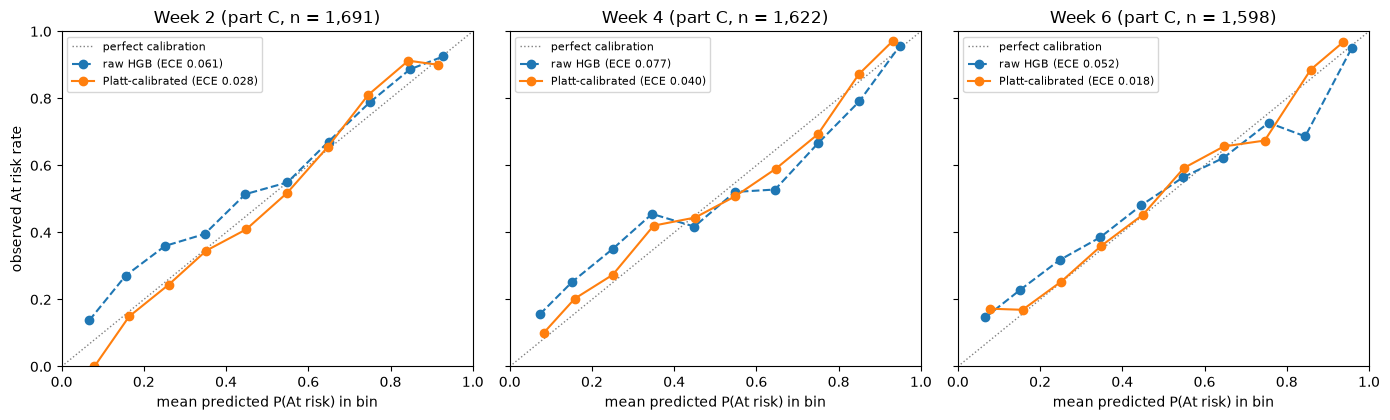

In [19]:
# [Table: raw vs Platt-calibrated, T3b] and [Figure: reliability diagram]
t3b, rel = [], {}
for T in CHECKPOINTS:
    pc = data[T]["pcal"]
    F = models[T]["F"]
    y = pc.meta_y.to_numpy()
    p_raw = models[T]["hgb"].predict_proba(pc[F])[:, 1]
    ia, ib, ic = [te for _, te in StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RS).split(pc[F], y, groups=pc.meta_id_student)]
    platt = LogisticRegression(random_state=RS).fit(logit(p_raw[ia]).reshape(-1, 1), y[ia])
    p_cal = platt.predict_proba(logit(p_raw).reshape(-1, 1))[:, 1]
    yc, rc_, cc_ = y[ic], p_raw[ic], p_cal[ic]
    t3b.append(dict(model="HGB", week=WEEK[T], n_part_C=len(ic), at_risk_rate=yc.mean(), pr_auc=average_precision_score(yc, rc_),
                    brier_raw=brier_score_loss(yc, rc_), brier_platt=brier_score_loss(yc, cc_),
                    ece_raw=ece_score(yc, rc_), ece_platt=ece_score(yc, cc_)))
    rel[T] = (yc, rc_, cc_)
t3b = pd.DataFrame(t3b)
EXP_T3B = dict(n_part_C=[1691, 1622, 1598], pr_auc=[0.732, 0.718, 0.772], brier_raw=[0.213, 0.215, 0.193],
               brier_platt=[0.209, 0.211, 0.190], ece_raw=[0.061, 0.077, 0.052], ece_platt=[0.028, 0.040, 0.018])
for col, v in EXP_T3B.items():
    got = t3b[col].round(3).tolist() if col != "n_part_C" else t3b[col].tolist()
    check("4.4", f"raw vs Platt: {col} by week = {v}", got == v, got)
check("4.4", "Platt scaling lowers Brier score and ECE at every week",
      (t3b.brier_platt < t3b.brier_raw).all() and (t3b.ece_platt < t3b.ece_raw).all())
display(t3b.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
for ax, T in zip(axes, CHECKPOINTS):
    yc, rc_, cc_ = rel[T]
    ax.plot([0, 1], [0, 1], ls=":", color="grey", lw=1, label="perfect calibration")
    for p_, lab, st in ((rc_, "raw HGB", "--"), (cc_, "Platt-calibrated", "-")):
        b = np.minimum((p_ * N_BINS).astype(int), N_BINS - 1)
        g = pd.DataFrame(dict(p=p_, y=yc, b=b)).groupby("b").agg(mp=("p", "mean"), ob=("y", "mean"))
        ax.plot(g.mp, g.ob, ls=st, marker="o", label=f"{lab} (ECE {ece_score(yc, p_):.3f})")
    ax.set_title(f"Week {WEEK[T]} (part C, n = {len(yc):,})")
    ax.set_xlabel("mean predicted P(At risk) in bin")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("observed At risk rate")
plt.tight_layout()
plt.show()

# 5. Conformal prediction
## 5.1 Class-conditional LAC with three-round cross-fitting
For each class c, the non-conformity score is 1 − p(true class). The threshold q_c is the
⌈(n_c + 1)(1 − α)⌉-th smallest score of class c on the threshold fold. A label is in the set
when its score is ≤ q_c. A set is then {*At risk*}, {*Not at risk*}, ambiguous (both labels) or
empty. With α = 0.10, each class should be covered at least 90% of the time. The thresholds
for each rotation are shown below.

In [20]:
qt = pd.DataFrame(q_rows)
qt[(qt.model == "HGB") & (qt.alpha == ALPHA)].round(4)

,model,week,rotation,alpha,q_at_risk,q_not_at_risk
1,HGB,2,0,0.1,0.7279,0.6474
5,HGB,2,1,0.1,0.6787,0.6568
9,HGB,2,2,0.1,0.6940,0.6257
25,HGB,4,0,0.1,0.7280,0.6120
29,HGB,4,1,0.1,0.6989,0.6228
33,HGB,4,2,0.1,0.7293,0.5927
49,HGB,6,0,0.1,0.7608,0.6284
53,HGB,6,1,0.1,0.6978,0.6224
57,HGB,6,2,0.1,0.7546,0.6020


## 5.2 The 100 re-split coverage check at α = 0.10
At each checkpoint, the **whole** `pcal` partition is re-divided 100 times (seeds 0–99) into
three student-grouped, label-stratified parts of about a third each:

- part A fits Platt scaling,
- part B fits the LAC thresholds,
- part C measures coverage.

HGB is **not** refitted; it stays fixed from `fit`. This shows how much coverage varies with the
split.

*Runtime: about 15 minutes. Each student-grouped split takes about 3 seconds, and there are 300 of them.*

In [21]:
# [100 re-split coverage check]
rs_rows = []
for T in CHECKPOINTS:
    pc = data[T]["pcal"]
    F = models[T]["F"]
    z = logit(models[T]["hgb"].predict_proba(pc[F])[:, 1])
    y, st = pc.meta_y.to_numpy(), pc.meta_id_student.to_numpy()
    for seed in range(N_RESPLITS):
        ia, ib, ic = [te for _, te in StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=seed).split(pc[F], y, groups=st)]
        if set(st[ia]) & set(st[ib]) or set(st[ia]) & set(st[ic]) or set(st[ib]) & set(st[ic]):
            check("5.2", "no student in two parts of a re-split", False, f"Week {WEEK[T]} seed {seed}")
        pp = LogisticRegression(random_state=RS).fit(z[ia].reshape(-1, 1), y[ia]).predict_proba(z.reshape(-1, 1))[:, 1]
        s = make_sets(pp[ic], lac_thresholds(pp[ib], y[ib], ALPHA))
        yc = y[ic]
        rs_rows.append(dict(week=WEEK[T], seed=seed, n_part_C=len(ic), cov_at_risk=np.isin(s[yc == 1], [SET_R, SET_A]).mean(),
                            cov_not_at_risk=np.isin(s[yc == 0], [SET_N, SET_A]).mean(), ambiguous=(s == SET_A).mean()))
rs = pd.DataFrame(rs_rows)
check("5.2", f"no student in two parts of any of the {3 * N_RESPLITS} re-splits", True)
rs_sum = []
for w, g in rs.groupby("week"):
    for cls, col in (("At risk", "cov_at_risk"), ("Not at risk", "cov_not_at_risk")):
        rs_sum.append(dict(week=w, true_class=cls, mean=g[col].mean(), min=g[col].min(), max=g[col].max(),
                           splits_below_0_90=int((g[col] < 0.90).sum()), mean_ambiguous_share=g.ambiguous.mean()))
rs_sum = pd.DataFrame(rs_sum)
lo, hi = round(rs_sum["mean"].min(), 3), round(rs_sum["mean"].max(), 3)
FULL_RUN = N_RESPLITS == 100           # the expected values below hold only for the full 100 splits
if FULL_RUN:
    check("5.2", "100-split mean coverage between 0.898 and 0.900", (lo, hi) == (0.898, 0.900), (lo, hi))
else:
    skipped("5.2", "100-split mean coverage between 0.898 and 0.900", f"quick run, N_RESPLITS = {N_RESPLITS}")
path = os.path.join(PILOT_DIR, "ext_B8_coverage_R100.csv")
if FULL_RUN and os.path.exists(path):
    sv = pd.read_csv(path)
    sv = sv[sv.row_type == "per_seed"].sort_values(["checkpoint", "seed"]).reset_index(drop=True)
    mine = rs.sort_values(["week", "seed"]).reset_index(drop=True)
    check("5.2", f"all 300 per-split coverages identical to {path}",
          np.allclose(mine.cov_at_risk, sv.coverage_at_risk, atol=1e-12, rtol=0)
          and np.allclose(mine.cov_not_at_risk, sv.coverage_not_at_risk, atol=1e-12, rtol=0))
else:
    skipped("5.2", "100-split coverages identical to the saved pilot file",
            "file not found" if FULL_RUN else f"quick run, N_RESPLITS = {N_RESPLITS}")
if FULL_RUN:
    check("5.2", "100-split coverage range 0.856 to 0.934", (round(rs_sum["min"].min(), 3), round(rs_sum["max"].max(), 3)) == (0.856, 0.934),
          (round(rs_sum["min"].min(), 3), round(rs_sum["max"].max(), 3)))
else:
    skipped("5.2", "100-split coverage range 0.856 to 0.934", f"quick run, N_RESPLITS = {N_RESPLITS}")
rs_sum.round(3)

,week,true_class,mean,min,max,splits_below_0_90,mean_ambiguous_share
0,2,At risk,0.900,0.856,0.932,53,0.587
1,2,Not at risk,0.900,0.859,0.931,43,0.587
2,4,At risk,0.900,0.856,0.930,47,0.560
3,4,Not at risk,0.899,0.860,0.934,51,0.560
4,6,At risk,0.898,0.858,0.933,51,0.486
5,6,Not at risk,0.900,0.864,0.926,49,0.486


## 5.3 Coverage per class and prediction-set types by α (Table B10, including the α sweep)
At α = 0.10, which is the primary setting, coverage is the **100-split mean** from §5.2. At the
other α values coverage comes from the single cross-fitted split. Set shares come from the
cross-fitted split at every α.

In [22]:
# [Table B10] Coverage and prediction-set types by alpha
b10 = []
for a in ALPHAS:
    for T in CHECKPOINTS:
        sub_ = pred[pred.checkpoint == T]
        s, y = sub_[f"set_a{a:.2f}"], sub_.y
        cr, cn = s[y == 1].isin([SET_R, SET_A]).mean(), s[y == 0].isin([SET_N, SET_A]).mean()
        if a == ALPHA:
            g = rs_sum[rs_sum.week == WEEK[T]].set_index("true_class")["mean"]
            cr, cn, src = g["At risk"], g["Not at risk"], "100-split mean"
        else:
            src = "cross-fitted split"
        b10.append({"alpha": a, "week": WEEK[T], "coverage At risk": round(cr, 3), "coverage Not at risk": round(cn, 3),
                    "{At risk} %": round(100 * (s == SET_R).mean(), 1), "{Not at risk} %": round(100 * (s == SET_N).mean(), 1),
                    "ambiguous %": round(100 * (s == SET_A).mean(), 1), "empty %": round(100 * (s == SET_E).mean(), 1),
                    "coverage source": src})
b10 = pd.DataFrame(b10)
EXP_AMB = {0.05: [75.8, 71.2, 66.9], 0.10: [58.1, 56.2, 49.2], 0.15: [42.6, 43.0, 34.3], 0.20: [32.0, 30.0, 21.4]}
for a, v in EXP_AMB.items():
    got = b10[b10.alpha == a]["ambiguous %"].tolist()
    check("5.3", f"alpha {a}: ambiguous share by week = {v} %", got == v, got)
check("5.3", "no empty set at any alpha", (b10["empty %"] == 0).all())
check("5.3", "alpha = 0.10 single-label shares match Table B10 (23.1/18.8, 23.5/20.3, 25.6/25.2)",
      b10[b10.alpha == 0.10][["{At risk} %", "{Not at risk} %"]].values.tolist() == [[23.1, 18.8], [23.5, 20.3], [25.6, 25.2]])
b10

,alpha,week,coverage At risk,coverage Not at risk,{At risk} %,{Not at risk} %,ambiguous %,empty %,coverage source
0,0.05,2,0.949,0.947,14.7,9.5,75.8,0.0,cross-fitted split
1,0.05,4,0.950,0.948,17.0,11.8,71.2,0.0,cross-fitted split
2,0.05,6,0.950,0.954,17.8,15.4,66.9,0.0,cross-fitted split
3,0.10,2,0.900,0.900,23.1,18.8,58.1,0.0,100-split mean
4,0.10,4,0.900,0.899,23.5,20.3,56.2,0.0,100-split mean
5,0.10,6,0.898,0.900,25.6,25.2,49.2,0.0,100-split mean
6,0.15,2,0.847,0.848,30.1,27.3,42.6,0.0,cross-fitted split
7,0.15,4,0.852,0.853,29.0,27.9,43.0,0.0,cross-fitted split
8,0.15,6,0.856,0.848,32.7,33.0,34.3,0.0,cross-fitted split
9,0.20,2,0.802,0.809,34.6,33.3,32.0,0.0,cross-fitted split


## 5.4 Prediction errors without action (Table 6)
OULAD records no interventions, so every outcome here is "without action". For each predictor,
the table counts students predicted *At risk* who actually passed, and students predicted *Not at
risk* who failed or withdrew. The rule-based flag fires on no clicks in the last 7 days **or** at
least one overdue assessment.

In [23]:
# [Table 6] Prediction errors (initial prediction, and each week)
PASSED, FAILED = ["Pass", "Distinction"], ["Fail", "Withdrawn"]
pred["rule_flag"] = (pred.clicks7 == 0) | (pred.n_overdue >= 1)
PREDICTORS = {"Rule-based flag": ("binary", "rule_flag"), "Logistic Regression, p >= 0.5": ("prob", "p_lr"),
              "HGB, p >= 0.5": ("prob", "p"), "Logistic Regression + conformal sets": ("set", "set_lr"),
              "HGB + conformal sets": ("set", "set")}


def errors(df):
    rows = []
    for name, (kind, col) in PREDICTORS.items():
        if kind == "binary":
            ar, na = df[df[col]], df[~df[col]]
        elif kind == "prob":
            ar, na = df[df[col] >= 0.5], df[df[col] < 0.5]
        else:
            ar, na = df[df[col] == SET_R], df[df[col] == SET_N]
        npass, nfail = int(ar.final_result.isin(PASSED).sum()), int(na.final_result.isin(FAILED).sum())
        rows.append({"predictor": name, "predicted At risk (n)": len(ar), "of whom passed (n)": npass,
                     "of whom passed (%)": round(100 * npass / len(ar), 1), "predicted Not at risk (n)": len(na),
                     "of whom failed or withdrew (n)": nfail, "of whom failed or withdrew (%)": round(100 * nfail / len(na), 1),
                     "left ambiguous (%)": round(100 * (df[col] == SET_A).mean(), 1) if kind == "set" else np.nan})
    return pd.DataFrame(rows)


init = pred.sort_values(["eid", "checkpoint"]).drop_duplicates("eid", keep="first")
t6 = errors(init)
EXP_T6 = {"Rule-based flag": [1155, 323, 3924, 1648], "Logistic Regression, p >= 0.5": [2366, 818, 2713, 932],
          "HGB, p >= 0.5": [2320, 780, 2759, 940], "Logistic Regression + conformal sets": [1110, 262, 1025, 239],
          "HGB + conformal sets": [1173, 267, 957, 249]}
for name, v in EXP_T6.items():
    got = t6.set_index("predictor").loc[name, ["predicted At risk (n)", "of whom passed (n)", "predicted Not at risk (n)",
                                               "of whom failed or withdrew (n)"]].astype(int).tolist()
    check("5.4", f"Table 6 initial prediction, {name} = {v}", got == v, got)
print(f"Initial prediction = each enrolment's first eligible checkpoint ({len(init):,} enrolments: "
      f"{init.week.value_counts().sort_index().to_dict()})")
display(t6)
t6w = pd.concat([errors(g).assign(week=w) for w, g in pred.groupby("week")], ignore_index=True)
t6w = t6w[["week"] + [c for c in t6w.columns if c != "week"]]
display(t6w)

Initial prediction = each enrolment's first eligible checkpoint (5,079 enrolments: {2: 5077, 4: 2})


,predictor,predicted At risk (n),of whom passed (n),of whom passed (%),predicted Not at risk (n),of whom failed or withdrew (n),of whom failed or withdrew (%),left ambiguous (%)
0,Rule-based flag,1155,323,28.0,3924,1648,42.0,NaN
1,"Logistic Regression, p >= 0.5",2366,818,34.6,2713,932,34.4,NaN
2,"HGB, p >= 0.5",2320,780,33.6,2759,940,34.1,NaN
3,Logistic Regression + conformal sets,1110,262,23.6,1025,239,23.3,58.0
4,HGB + conformal sets,1173,267,22.8,957,249,26.0,58.1


,week,predictor,predicted At risk (n),of whom passed (n),of whom passed (%),predicted Not at risk (n),of whom failed or withdrew (n),of whom failed or withdrew (%),left ambiguous (%)
0,2,Rule-based flag,1154,323,28.0,3923,1648,42.0,NaN
1,2,"Logistic Regression, p >= 0.5",2365,818,34.6,2712,932,34.4,NaN
2,2,"HGB, p >= 0.5",2318,779,33.6,2759,940,34.1,NaN
3,2,Logistic Regression + conformal sets,1109,262,23.6,1024,239,23.3,58.0
4,2,HGB + conformal sets,1171,266,22.7,957,249,26.0,58.1
5,4,Rule-based flag,1326,391,29.5,3543,1335,37.7,NaN
6,4,"Logistic Regression, p >= 0.5",1830,536,29.3,3039,976,32.1,NaN
7,4,"HGB, p >= 0.5",1843,591,32.1,3026,1018,33.6,NaN
8,4,Logistic Regression + conformal sets,1191,266,22.3,1144,237,20.7,52.0
9,4,HGB + conformal sets,1146,263,22.9,987,221,22.4,56.2


## 5.5 Set stability from Week 2 to Week 6 (Table B8)
These are the enrolments assessed at Weeks 2, 4 and 6, using cross-fitted α = 0.10 sets and
ignoring any routing action. The table shows how often a student's set stays the same, how
often an ambiguous set becomes a single label (and whether that label is correct), and how
often a set moves to the opposite label.

In [24]:
# [Table B8] Prediction-set transitions, Week 2 -> Week 6
SHORT = {SET_R: "{At risk}", SET_N: "{Not at risk}", SET_A: "ambiguous", SET_E: "{}"}
order = ["{At risk}", "ambiguous", "{Not at risk}", "{}"]
w2 = pred[pred.week == 2].set_index("eid")
wide = pred.pivot(index="eid", columns="week", values="set").dropna().map(SHORT.get)
ys = pred.drop_duplicates("eid").set_index("eid")
wide["y"] = ys.loc[wide.index, "y"]
mat = pd.crosstab(wide[2], wide[6]).reindex(index=order, columns=order, fill_value=0)
mat.index.name, mat.columns.name = "Week 2 set", "Week 6 set"
display(mat)

b8 = []
for s2, opposite in (("{At risk}", "{Not at risk}"), ("ambiguous", None), ("{Not at risk}", "{At risk}")):
    g = wide[wide[2] == s2]
    n_w2 = int((w2.set.map(SHORT) == s2).sum())
    same = int((g[6] == s2).sum())
    if s2 == "ambiguous":
        changed = int(g[6].isin(["{At risk}", "{Not at risk}"]).sum())
        opp = np.nan
    else:
        changed = int((g[6] == "ambiguous").sum())
        opp = int((g[6] == opposite).sum())
    b8.append({"Week 2 set": s2, "assessed at both": len(g), "same at Week 6": same, "same %": round(100 * same / len(g), 1),
               "became ambiguous / clear": changed, "changed %": round(100 * changed / len(g), 1), "moved to opposite label": opp,
               "withdrew before Week 6": n_w2 - len(g), "withdrew % (of Week 2 set)": round(100 * (n_w2 - len(g)) / n_w2, 1),
               "share actually At risk %": round(100 * g.y.mean(), 1)})
b8 = pd.DataFrame(b8)
amb = wide[wide[2] == "ambiguous"]
amb1 = amb[amb[6].isin(["{At risk}", "{Not at risk}"])]
correct = int((((amb1[6] == "{At risk}") & (amb1.y == 1)) | ((amb1[6] == "{Not at risk}") & (amb1.y == 0))).sum())
check("5.5", "4,792 enrolments assessed at Weeks 2, 4 and 6", len(wide) == 4792)
check("5.5", "Table B8 rows (assessed, same, changed, opposite, withdrew)",
      b8[["assessed at both", "same at Week 6", "became ambiguous / clear", "withdrew before Week 6"]].values.tolist()
      == [[1009, 674, 324, 162], [2838, 1757, 1081, 111], [945, 622, 275, 12]] and b8["moved to opposite label"].fillna(-1).tolist() == [11, -1, 48],
      b8.values.tolist())
check("5.5", "831 of 1,081 ambiguous cases that became clear got the correct label", (len(amb1), correct) == (1081, 831), (len(amb1), correct))
display(b8)
print(f"Ambiguous at Week 2 that became a single label by Week 6: {len(amb1):,}; correct label: {correct:,} ({100 * correct / len(amb1):.1f}%)")

Week 6 set,{At risk},ambiguous,{Not at risk},{}
Week 2 set,,,,
{At risk},674,324,11,0
ambiguous,504,1757,577,0
{Not at risk},48,275,622,0
{},0,0,0,0


,Week 2 set,assessed at both,same at Week 6,same %,became ambiguous / clear,changed %,moved to opposite label,withdrew before Week 6,withdrew % (of Week 2 set),share actually At risk %
0,{At risk},1009,674,66.8,324,32.1,11.0,162,13.8,73.6
1,ambiguous,2838,1757,61.9,1081,38.1,NaN,111,3.8,42.8
2,{Not at risk},945,622,65.8,275,29.1,48.0,12,1.3,25.1


Ambiguous at Week 2 that became a single label by Week 6: 1,081; correct label: 831 (76.9%)


# 6. Routing
## 6.1 Routing rules (proposed method; `routing_engine.py`)
Routing runs at Weeks 2, 4 and 6, separately in each module presentation. At each checkpoint,
every eligible enrolment gets exactly one status.

**1. Route from the prediction set** (α = 0.10; "high risk" means calibrated p ≥ 0.5):

| prediction set | route |
|---|---|
| {*At risk*} | Contact candidate |
| empty {} | Review candidate |
| {*Not at risk*} | Monitor |
| ambiguous, p ≥ 0.5 | Review candidate ("high risk") |
| ambiguous, p < 0.5, Week 2 or 4 | **Defer**: wait for more evidence |
| ambiguous, p < 0.5, Week 6, *persistent* | Review candidate ("persistent") |
| ambiguous, p < 0.5, Week 6, not persistent | Monitor (uncertainty flag) |

A case is *persistent* when its set contained *At risk* at the previous checkpoint and still
does now.

**2. Repeat-selection and follow-up rules.**
- A student who was **contacted** earlier is never contacted again.
  - If they were already reviewed too, they get **No new action**.
  - Otherwise, if p ≥ 0.5 they become a **follow-up Review candidate**; if not, they are
    Monitored.
- A student who was **reviewed** earlier can never be a Review candidate again.

**3. Capacity** (per module, in whole places):
- **Contact.** Contact places = min(K, B − contacts already made). Candidates are ranked with
  persistent cases first, then by p. The top ones get **Contact**; the others wait in **Contact
  Waiting**.
- **Review.** R places go first to *new* Review candidates, ranked by p and then persistence. The
  others wait in **Review Waiting**.
- **Follow-up Reviews** only get Review places left over after the new candidates. A follow-up
  candidate without a place is Monitored, never put on Waiting.
- Unused places are not carried over, and are not moved between Contact and Review.

**Comparison methods** share the same capacity:

| method | rule |
|---|---|
| Rule-based alerts | flag = no clicks in the last 7 days or ≥ 1 overdue assessment; the top-ranked flags get Contact, the next R get a matched Review |
| HGB Top-K | everyone ranked by calibrated p; the top K get Contact, the next R get Review |
| Probability-threshold deferral | p ≥ upper: Contact candidate; between lower and upper: Defer (Weeks 2/4) or Monitor (Week 6); otherwise Monitor |
| Conformal without persistence | proposed rules, but no persistence rule |
| Conformal without separate Waiting | proposed rules, but candidates without a place go to Defer instead of Waiting |

## 6.2 Capacity and the six runs
`capacity.py` sets **K = 10** contacts and **R = 5** reviews per checkpoint, and **B = 25**
unique contacts across the three checkpoints, for each of the five `pcal` module presentations.
Every run must pass `routing_engine.check_routing` as well as the explicit checks below.

In [25]:
route_pred = pred[["checkpoint", "week", "eid", "student", "cohort", "p", "set", "upper", "lower", "y", "clicks7", "n_overdue"]].copy()
modules = sorted(route_pred.cohort.unique())
cap = capacity_for_all_modules(modules, default=ModuleCapacity(K_DEFAULT, R_DEFAULT, B_DEFAULT))
print_capacity_table(cap)
pcal_ids = set(enrol.meta_enrolment_id)
NAME = {"rules": "Rule-based alerts", "topk": "HGB Top-K", "threshold": "Probability-threshold deferral",
        "conf_no_persistence": "Conformal without persistence", "conf_no_waiting": "Conformal without separate Waiting",
        "proposed": "Proposed policy"}
SEL, WAIT = [RE.CONTACT, RE.REVIEW], [RE.CW, RE.RW]
logs, caps_logs = {}, {}
for m in RE.METHODS:
    log, caps = RE.run_routing(route_pred, m, cap)
    RE.check_routing(log, caps, route_pred, m, cap, allowed_ids=pcal_ids)
    check("6.2", f"{NAME[m]}: routing_engine.check_routing passes", True)
    # explicit checks
    check("6.2", f"{NAME[m]}: Contact <= K and Review <= R at every module and week",
          (caps.contact_used <= caps.K_t).all() and (caps.contact_used <= caps.contact_places_available).all() and (caps.review_used <= caps.R_t).all())
    check("6.2", f"{NAME[m]}: unique contacts <= B in every module", (log[log.status == RE.CONTACT].groupby("cohort").eid.nunique() <= B_DEFAULT).all())
    check("6.2", f"{NAME[m]}: no one contacted twice and no one reviewed twice",
          (log[log.status == RE.CONTACT].eid.value_counts() <= 1).all() and (log[log.status == RE.REVIEW].eid.value_counts() <= 1).all())
    check("6.2", f"{NAME[m]}: only qualifying cases are put on Waiting",
          (log.loc[log.status == RE.CW, "route"] == RE.RC).all() and (log.loc[log.status == RE.RW, "route"] == RE.RR).all())
    check("6.2", f"{NAME[m]}: one status per eligible enrolment per week, pcal only",
          not log.duplicated(["eid", "checkpoint"]).any() and len(log) == len(route_pred) and set(log.eid) <= pcal_ids)
    logs[m], caps_logs[m] = log, caps
print("All six methods pass every routing check.")

module        K Wk2  K Wk4  K Wk6    R    B  source
BBB_2013B        10     10     10    5   25  default
DDD_2013B        10     10     10    5   25  default
EEE_2014B        10     10     10    5   25  default
FFF_2013B        10     10     10    5   25  default
GGG_2014B        10     10     10    5   25  default


All six methods pass every routing check.


In [26]:
# Cross-check against the saved v5 routing logs (pilot_routing_v5.py)
for m, f in zip(RE.METHODS, ["m0_rules", "m1_topk", "m2_threshold", "m3_conf_no_persistence", "m4_conf_no_waiting", "m5_proposed"]):
    path = os.path.join(PILOT_DIR, "v5_followup_last", f"comparison_log_{f}.csv")
    if not os.path.exists(path):
        skipped("6.2", f"{NAME[m]}: identical to the saved v5 log", "file not found")
        continue
    sv = pd.read_csv(path, usecols=["eid", "checkpoint", "status", "route"])
    mm = logs[m][["eid", "checkpoint", "status", "route"]].merge(sv, on=["eid", "checkpoint"], how="outer", suffixes=("", "_s"), indicator=True)
    check("6.2", f"{NAME[m]}: status and route identical to the saved v5 log",
          (mm._merge == "both").all() and (mm.status == mm.status_s).all() and (mm.route.fillna("") == mm.route_s.fillna("")).all())
print("Saved-log cross-check done.")

Saved-log cross-check done.


## 6.3 Routing table: reach, false-positive contacts, review precision and cumulative reach
*Reached* means the student was given a Contact or Review place. The table counts the 2,480 *At
risk* `pcal` enrolments reached by Weeks 2 / 4 / 6. Review precision is the share of *new*
Reviews given to students who really were *At risk*; follow-up Reviews are reported separately.

,method,At risk reached by Week 2 / 4 / 6,reached by Week 6 (%),contacts At risk / all,false-positive contacts,new Reviews At risk (%),follow-up Reviews (At risk)
0,Rule-based alerts,48 / 101 / 133,5.4,91 / 125 (72.8%),34,76.0,0 (0)
1,HGB Top-K,67 / 124 / 163,6.6,108 / 125 (86.4%),17,88.0,0 (0)
2,Probability-threshold deferral,67 / 124 / 163,6.6,108 / 125 (86.4%),17,88.0,0 (0)
3,Conformal without persistence,61 / 116 / 152,6.1,108 / 125 (86.4%),17,60.0,0 (0)
4,Conformal without separate Waiting,61 / 116 / 152,6.1,108 / 125 (86.4%),17,60.0,0 (0)
5,Proposed policy,61 / 116 / 152,6.1,108 / 125 (86.4%),17,60.0,0 (0)


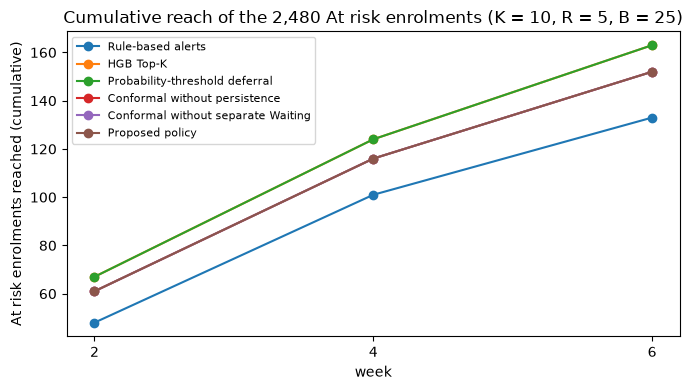

In [27]:
# [Table: routing comparison]
N_AR = int(pred.drop_duplicates("eid").y.sum())
rt = []
for m in RE.METHODS:
    log = logs[m]
    o = RE.outcome_measures(log, caps_logs[m])
    con = log[log.status == RE.CONTACT]
    rev = log[log.status == RE.REVIEW]
    fu = rev[rev.review_reason == "follow-up after contact"]
    new = rev[rev.review_reason != "follow-up after contact"]
    rt.append({"method": NAME[m],
               "At risk reached by Week 2 / 4 / 6": " / ".join(str(o[f"At risk selected by Week {w} (n)"]) for w in (2, 4, 6)),
               "reached by Week 6 (%)": round(100 * o["At risk selected by Week 6 (n)"] / N_AR, 1),
               "contacts At risk / all": f"{int(con.y.sum())} / {len(con)} ({100 * con.y.mean():.1f}%)",
               "false-positive contacts": int((con.y == 0).sum()),
               "new Reviews At risk (%)": round(100 * new.y.mean(), 1),
               "follow-up Reviews (At risk)": f"{len(fu)} ({int(fu.y.sum())})",
               "_reached": [o[f"At risk selected by Week {w} (n)"] for w in (2, 4, 6)]})
rt = pd.DataFrame(rt)
EXP_RT = {"Rule-based alerts": ([48, 101, 133], "91 / 125 (72.8%)", 34, 76.0),
          "HGB Top-K": ([67, 124, 163], "108 / 125 (86.4%)", 17, 88.0),
          "Probability-threshold deferral": ([67, 124, 163], "108 / 125 (86.4%)", 17, 88.0),
          "Conformal without persistence": ([61, 116, 152], "108 / 125 (86.4%)", 17, 60.0),
          "Conformal without separate Waiting": ([61, 116, 152], "108 / 125 (86.4%)", 17, 60.0),
          "Proposed policy": ([61, 116, 152], "108 / 125 (86.4%)", 17, 60.0)}
for r in rt.itertuples(index=False):
    got = (r[7], r[3], r[4], r[5])
    check("6.3", f"routing table row: {r[0]}", got == EXP_RT[r[0]], got)
display(rt.drop(columns="_reached"))

fig, ax = plt.subplots(figsize=(7, 4))
for r in rt.itertuples(index=False):
    ax.plot([2, 4, 6], r[7], marker="o", label=r[0])
ax.set_xticks([2, 4, 6]); ax.set_xlabel("week"); ax.set_ylabel("At risk enrolments reached (cumulative)")
ax.set_title(f"Cumulative reach of the {N_AR:,} At risk enrolments (K = 10, R = 5, B = 25)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6.4 Delay causes and *Unserved due to capacity* (Table B6)
Each of the 2,480 *At risk* enrolments gets **one** delay cause. The causes are counted only up
to the first checkpoint at which the student got a place. Brackets show how many with that
cause were reached later.

- **Reached without delay:** got a place at the first checkpoint at which they qualified.
- **Deferred first:** deferred for uncertain evidence before qualifying, and never left without a
  place.
- **Qualified, no place:** qualified at least once without getting a place.
- **Deferred, then no place:** both of the above.
- **Never a candidate:** never qualified.

**Unserved due to capacity** counts *At risk* students who were a Contact or Review candidate
without a place at some checkpoint and were **never reached**. *Withdrew while waiting* counts
the unserved students whose last status was Waiting and who left before Week 6.

In [28]:
# [Table B6] Delay causes for the At risk enrolments
A6_NAME = {"none": "Reached without delay", "uncertainty-related": "Deferred first", "capacity-related": "Qualified, no place",
           "combined": "Deferred, then no place", "never a candidate": "Never a candidate"}
b6, b6_counts = [], {}
for m in RE.METHODS:
    log = logs[m]
    last = log.sort_values("checkpoint").drop_duplicates("eid", keep="last").set_index("eid")
    ar_ids = last.index[last.y == 1]
    reached = set(log.loc[log.status.isin(SEL), "eid"])
    unplaced = set(log.loc[log.route.isin(RE.CAND_ROUTES) & ~log.status.isin(SEL), "eid"])
    dt = RE.delay_types(log).reindex(ar_ids).map(A6_NAME)
    row = {"method": NAME[m]}
    cnt = []
    for k in A6_NAME.values():
        ids = dt.index[dt == k]
        n, nl = len(ids), len(set(ids) & reached)
        row[k] = f"{n:,}" if k in ("Reached without delay", "Never a candidate") else f"{n:,} ({nl:,})"
        cnt += [n, nl]
    unserved = [e for e in ar_ids if e not in reached and e in unplaced]
    wd_wait = [e for e in unserved if last.loc[e, "status"] in WAIT and last.loc[e, "week"] < 6]
    row["Reached by Week 6"] = len(set(ar_ids) & reached)
    row["Unserved due to capacity"] = len(unserved)
    row["of whom withdrew while waiting"] = len(wd_wait)
    b6.append(row)
    b6_counts[NAME[m]] = cnt + [row["Reached by Week 6"], len(unserved), len(wd_wait)]
    check("6.4", f"{NAME[m]}: the five delay causes sum to {N_AR:,}", sum(cnt[0::2]) == N_AR)
b6 = pd.DataFrame(b6)
EXP_B6 = {"Rule-based alerts": [73, 73, 0, 0, 1394, 60, 0, 0, 1013, 0, 133, 1334, 0],
          "HGB Top-K": [163, 163, 0, 0, 0, 0, 0, 0, 2317, 0, 163, 0, 0],
          "Probability-threshold deferral": [67, 67, 12, 12, 689, 77, 539, 7, 1173, 0, 163, 1144, 148],
          "Conformal without persistence": [62, 62, 4, 4, 1515, 84, 295, 2, 604, 0, 152, 1724, 222],
          "Conformal without separate Waiting": [62, 62, 4, 4, 1515, 84, 588, 2, 311, 0, 152, 2017, 0],
          "Proposed policy": [62, 62, 4, 4, 1515, 84, 588, 2, 311, 0, 152, 2017, 222]}
for k, v in EXP_B6.items():
    check("6.4", f"Table B6 row: {k}", b6_counts[k] == v, b6_counts[k])
check("6.4", "proposed policy: Unserved = 2,017, of whom 222 withdrew while waiting",
      b6.set_index("method").loc["Proposed policy", ["Unserved due to capacity", "of whom withdrew while waiting"]].tolist() == [2017, 222])
b6

,method,Reached without delay,Deferred first,"Qualified, no place","Deferred, then no place",Never a candidate,Reached by Week 6,Unserved due to capacity,of whom withdrew while waiting
0,Rule-based alerts,73,0 (0),"1,394 (60)",0 (0),"1,013",133,1334,0
1,HGB Top-K,163,0 (0),0 (0),0 (0),"2,317",163,0,0
2,Probability-threshold deferral,67,12 (12),689 (77),539 (7),"1,173",163,1144,148
3,Conformal without persistence,62,4 (4),"1,515 (84)",295 (2),604,152,1724,222
4,Conformal without separate Waiting,62,4 (4),"1,515 (84)",588 (2),311,152,2017,0
5,Proposed policy,62,4 (4),"1,515 (84)",588 (2),311,152,2017,222


In [29]:
# Status of every eligible enrolment under the proposed policy, by week
pd.crosstab(logs["proposed"].status, logs["proposed"].week, margins=True)

week,2,4,6,All
status,,,,
Contact,50,50,25,125
Contact Waiting,1121,1055,1121,3297
Defer,1802,2038,0,3840
Monitor,957,1031,1300,3288
Monitor (uncertainty flag),0,0,249,249
No new action,0,10,33,43
Review,25,25,25,75
Review Waiting,1122,660,2041,3823
All,5077,4869,4794,14740


# 7. Explanation and fairness
## 7.1 Kernel SHAP explanation of one recommendation
The example is the Week 2 **Contact** recommendation with the highest calibrated risk under the
proposed policy. It is explained with Kernel SHAP (`interpret`'s `ShapKernel`), using the
calibrated model of the enrolment's own rotation: Platt applied to the HGB log-odds. The
background is 100 `fit` rows sampled with seed 42.

Kernel SHAP needs a numeric array, so categoricals become integer codes and missing numeric
values become a placeholder (−999). A wrapper turns them back into the original types and
missing values before predicting. The notebook checks that the wrapper gives exactly the same
probabilities as the model.

  0%|          | 0/1 [00:00<?, ?it/s]

Enrolment DDD_2013B_520092 (module DDD_2013B), Week 2: set {At risk}, calibrated p = 0.960 -> Contact
Background mean P(At risk) = 0.471; base + sum of SHAP = 0.960; Kernel SHAP 2.9 s


,feature,value,SHAP contribution to P(At risk)
0,n_not_yet_due,13,0.0901
1,days_since_last_activity,NaN,0.0708
2,highest_education,Lower Than A Level,0.0506
3,active_days,0,0.0461
4,imd_band,10-20,0.0456
5,prestart_clicks,0,0.0432
6,clicks_last7_homepage,0,0.0405
7,disability,Y,0.0345
8,clicks_total_homepage,0,0.0343
9,studied_credits,120,0.0334


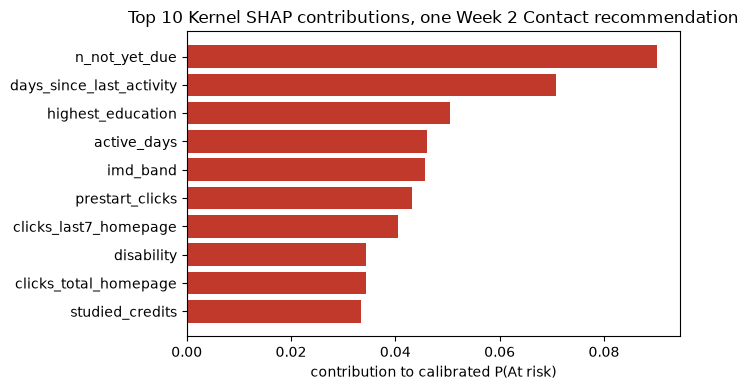

In [30]:
# [Kernel SHAP example]
prop = logs["proposed"]
ex_row = prop[(prop.week == 2) & (prop.status == RE.CONTACT)].sort_values(["p", "eid"], ascending=[False, True]).iloc[0]
T = 14
d, m = data[T], models[T]
F, cat_cols, cats = m["F"], m["cat_cols"], data[T]["cats"]
fit_, pcal_ = d["fit"], d["pcal"]
NUM_PH = -999.0
num_ph_cols = [c for c in ["days_since_last_activity", "mean_score_available"] if c in F]
check("7.1", "missing values only in features with a placeholder",
      not [c for c in F if c not in cat_cols and c not in num_ph_cols and (fit_[c].isna().any() or pcal_[c].isna().any())])
check("7.1", "no real value equals the placeholder", not any((fit_[c] == NUM_PH).any() or (pcal_[c] == NUM_PH).any() for c in num_ph_cols))


def to_codes(X):
    out = np.empty((len(X), len(F)))
    for j, c in enumerate(F):
        if c in cat_cols:
            out[:, j] = X[c].cat.codes.to_numpy().astype(float)
        else:
            v = X[c].to_numpy(dtype=float, na_value=np.nan)
            out[:, j] = np.where(np.isnan(v), NUM_PH, v) if c in num_ph_cols else v
    return out


def from_codes(A):
    A = np.atleast_2d(np.asarray(A, float))
    cols = {}
    for j, c in enumerate(F):
        if c in cat_cols:
            cols[c] = pd.Categorical.from_codes(np.rint(A[:, j]).astype(int), categories=cats[c])
        elif c in num_ph_cols:
            cols[c] = np.where(A[:, j] == NUM_PH, np.nan, A[:, j])
        else:
            cols[c] = A[:, j]
    return pd.DataFrame(cols, columns=F)


r = int(pcal_.set_index("meta_enrolment_id").loc[ex_row.eid, "fold"])
platt = m["platt"]["HGB"][r]


def predict_cal(X):
    return platt.predict_proba(logit(m["hgb"].predict_proba(X)[:, 1]).reshape(-1, 1))[:, 1]


def wrapper(A):
    p1 = predict_cal(from_codes(A))
    return np.column_stack([1 - p1, p1])


check("7.1", "wrapper reproduces the calibrated model exactly on every pcal row",
      np.array_equal(predict_cal(pcal_[F]), wrapper(to_codes(pcal_[F]))[:, 1]))
x = pcal_[pcal_.meta_enrolment_id == ex_row.eid]
check("7.1", "explained probability equals the routed cross-fitted p", abs(predict_cal(x[F])[0] - ex_row.p) < 1e-12)
background = fit_[F].sample(n=100, random_state=RS)
t0 = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    expl = ShapKernel(wrapper, to_codes(background), feature_names=F, feature_types=["continuous"] * len(F)).explain_local(to_codes(x[F]))
contrib = np.asarray(expl.data(0)["scores"], float)
base = float(wrapper(to_codes(background))[:, 1].mean())
shap_tab = pd.DataFrame({"feature": F, "value": [x[c].iloc[0] for c in F], "SHAP contribution to P(At risk)": contrib})
shap_tab = shap_tab.reindex(shap_tab["SHAP contribution to P(At risk)"].abs().sort_values(ascending=False).index).reset_index(drop=True)
print(f"Enrolment {ex_row.eid} (module {ex_row.cohort}), Week 2: set {ex_row.set}, calibrated p = {ex_row.p:.3f} -> {ex_row.status}")
print(f"Background mean P(At risk) = {base:.3f}; base + sum of SHAP = {base + contrib.sum():.3f}; Kernel SHAP {time.perf_counter() - t0:.1f} s")
display(shap_tab.head(10).round(4))
top = shap_tab.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(top.feature, top["SHAP contribution to P(At risk)"], color=np.where(top["SHAP contribution to P(At risk)"] > 0, "#c0392b", "#2e86c1"))
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("contribution to calibrated P(At risk)")
ax.set_title("Top 10 Kernel SHAP contributions, one Week 2 Contact recommendation")
plt.tight_layout()
plt.show()

## 7.2 Fairness of access with Fairlearn `MetricFrame` (age band and disability)
Among *At risk* enrolments, the notebook compares how often each group is deferred, put on
Waiting, reached by Week 6, or never reached, under the proposed policy and HGB Top-K. Groups
are disability (Y / N) and age band, with 35–55 and 55+ merged into "35 and over" because the
55+ group is very small. The 95% intervals for the largest gap between groups come from 1,000
bootstrap resamples **at student level**: all of a student's enrolments are resampled together.

In [31]:
# [Fairness: Fairlearn MetricFrame]
def access_table(log):
    rows = []
    for eid, h in log[log.y == 1].groupby("eid"):
        sel = h[h.status.isin(SEL)]
        rows.append(dict(eid=eid, student=h.student.iloc[0], ever_deferred=int((h.status == RE.DEFER).any()),
                         ever_waiting=int(h.status.isin(WAIT).any()), reached_by_week6=int(len(sel) > 0),
                         never_reached=int(len(sel) == 0)))
    return pd.DataFrame(rows)


MEASURES = ["ever_deferred", "ever_waiting", "reached_by_week6", "never_reached"]
attr_of = pred.drop_duplicates("eid").set_index("eid")[["disability", "age_band"]]
attr_of["age band (merged)"] = attr_of.age_band.map(AGE_MERGE)
check("7.2", "no missing or unexpected group value", attr_of["age band (merged)"].notna().all() and attr_of.disability.isin(["Y", "N"]).all())
rng = np.random.default_rng(RS)
fair = []
for pol in ("proposed", "topk"):
    acc = access_table(logs[pol])
    stu = pd.factorize(acc.student)[0]
    n_stu = stu.max() + 1
    W = np.stack([np.bincount(rng.integers(0, n_stu, n_stu), minlength=n_stu)[stu] for _ in range(N_BOOT)]).astype(float)
    for attr in ("disability", "age band (merged)"):
        grp = attr_of.loc[acc.eid, attr].to_numpy()
        mf = MetricFrame(metrics={"n": count}, y_true=acc[MEASURES[0]].to_numpy(), y_pred=acc[MEASURES[0]].to_numpy(),
                         sensitive_features=grp)
        for mm_ in MEASURES:
            v = acc[mm_].to_numpy(float)
            mf_m = MetricFrame(metrics=lambda yt, yp: float(np.mean(yp)), y_true=v, y_pred=v, sensitive_features=grp)
            groups = list(mf_m.by_group.index)
            boot = np.stack([(W[:, grp == g_] * v[grp == g_]).sum(1) / W[:, grp == g_].sum(1) for g_ in groups], axis=1)
            gaps = boot.max(1) - boot.min(1)
            row = {"policy": NAME[pol], "attribute": attr, "measure": mm_}
            for g_ in groups:
                row[f"{g_} (n = {int(mf.by_group['n'][g_])})"] = round(mf_m.by_group[g_], 3)
            row["largest gap"] = round(mf_m.difference(), 3)
            row["95% CI"] = f"[{np.percentile(gaps, 2.5):.3f}, {np.percentile(gaps, 97.5):.3f}]"
            fair.append(row)
fair = pd.DataFrame(fair)
for attr in ("disability", "age band (merged)"):
    display(fair[fair.attribute == attr].dropna(axis=1, how="all"))

,policy,attribute,measure,N (n = 2198),Y (n = 282),largest gap,95% CI
0,Proposed policy,disability,ever_deferred,0.446,0.379,0.066,"[0.011, 0.128]"
1,Proposed policy,disability,ever_waiting,0.853,0.844,0.009,"[0.001, 0.058]"
2,Proposed policy,disability,reached_by_week6,0.060,0.074,0.015,"[0.001, 0.045]"
3,Proposed policy,disability,never_reached,0.940,0.926,0.015,"[0.001, 0.045]"
8,HGB Top-K,disability,ever_deferred,0.000,0.000,0.000,"[0.000, 0.000]"
9,HGB Top-K,disability,ever_waiting,0.000,0.000,0.000,"[0.000, 0.000]"
10,HGB Top-K,disability,reached_by_week6,0.062,0.092,0.030,"[0.003, 0.067]"
11,HGB Top-K,disability,never_reached,0.938,0.908,0.030,"[0.003, 0.067]"


,policy,attribute,measure,largest gap,95% CI,0-35 (n = 1805),35 and over (n = 675)
4,Proposed policy,age band (merged),ever_deferred,0.059,"[0.017, 0.104]",0.422,0.481
5,Proposed policy,age band (merged),ever_waiting,0.059,"[0.027, 0.094]",0.868,0.809
6,Proposed policy,age band (merged),reached_by_week6,0.009,"[0.001, 0.028]",0.064,0.055
7,Proposed policy,age band (merged),never_reached,0.009,"[0.001, 0.028]",0.936,0.945
12,HGB Top-K,age band (merged),ever_deferred,0.000,"[0.000, 0.000]",0.000,0.000
13,HGB Top-K,age band (merged),ever_waiting,0.000,"[0.000, 0.000]",0.000,0.000
14,HGB Top-K,age band (merged),reached_by_week6,0.013,"[0.001, 0.033]",0.069,0.056
15,HGB Top-K,age band (merged),never_reached,0.013,"[0.001, 0.033]",0.931,0.944


# 8. Close
## 8.1 Every automated check

In [32]:
chk = pd.DataFrame(CHECKS)
print(f"{(chk.result == 'pass').sum()} passed, {(chk.result == 'FAIL').sum()} failed, {(chk.result == 'skipped').sum()} skipped "
      f"(skipped = an optional saved file to cross-check against was not found)")
display(chk.groupby("section").result.value_counts().unstack(fill_value=0))
check("8", "every automated check passed", (chk.result != "FAIL").all())
chk

177 passed, 0 failed, 0 skipped (skipped = an optional saved file to cross-check against was not found)


result,pass
section,
0,1
2.1,9
2.2,1
2.3,2
2.4,19
3.1,8
3.2,1
3.3,15
3.4,3


,section,check,result,detail
0,0,routing_engine.py uses the v5 defaults,pass,"{'FOLLOWUP_REVIEW': True, 'FOLLOWUP_LAST': Tru..."
1,2.1,Duplicate enrolment keys in studentInfo = 0,pass,
2,2.1,Duplicate enrolment keys in studentRegistratio...,pass,
3,2.1,Enrolments in studentInfo missing from student...,pass,
4,2.1,Enrolments in studentRegistration missing from...,pass,
5,2.1,"Duplicate (id_assessment, id_student) keys in ...",pass,
6,2.1,Submissions with an unknown id_assessment = 0,pass,
7,2.1,VLE rows (to Day 42) with an unknown site = 0,pass,
8,2.1,VLE rows (to Day 42) with no matching enrolmen...,pass,
9,2.1,VLE rows (to Day 42) with clicks <= 0 = 0,pass,


## 8.2 Map from report tables and figures to this notebook
| report item | notebook section | produced by |
|---|---|---|
| Table B1: partitions | §2.3 | `b1` |
| student-overlap removal (2,410) | §2.3 | overlap table |
| eligibility counts (1,377 withdrew by Day 14; 4,497 never eligible) | §2.2 | `elig_tab`, never-eligible reasons |
| data-preparation expected values | §2.4 | `exp` |
| Table B3: features | §3.2 | `b3` |
| marking delay, exam excluded, leakage checks | §3.1, §3.3 | checks |
| `mean_score_available` dropped at Weeks 2 and 4 | §3.6 | `drop_tab` |
| model performance (HGB, LR) and PR-AUC vs chance | §4.3 | `t3a` |
| raw vs Platt-calibrated (Brier, ECE) | §4.4 | `t3b` |
| reliability diagram | §4.4 | figure |
| LAC thresholds | §5.1 | `qt` |
| 100 re-split coverage check | §5.2 | `rs_sum` |
| Table B10: coverage and set types by α (α sweep) | §5.3 | `b10` |
| Table 6: prediction errors without action | §5.4 | `t6`, `t6w` |
| Table B8: set stability, Week 2 to Week 6 | §5.5 | `mat`, `b8` |
| §3.5 routing rules | §6.1 | text |
| routing comparison table and cumulative reach | §6.3 | `rt`, figure |
| Table B6: delay causes and Unserved (2,017 / 222) | §6.4 | `b6` |
| Kernel SHAP example | §7.1 | `shap_tab`, figure |
| fairness of access (Fairlearn) | §7.2 | `fair` |
| automated checks | §8.1 | `chk` |

*Not in this notebook:* the capacity-sensitivity and spending-schedule grids, global feature
importance and explanation stability. These come from separate pilot scripts.

In [33]:
print(f"Total runtime: {(time.time() - T_START) / 60:.1f} minutes")

Total runtime: 18.6 minutes
